**<center style="font-size:4em;">Data exploration notebook</center>**

# Initialization

## Loading data

In [1]:
import pandas as pd

# Load the dataset
file_path = '../../data/raw/sickness_table.csv'

df = pd.read_csv(file_path, index_col=0)

In [2]:
df.dtypes

date         object
n_sick        int64
calls       float64
n_duty        int64
n_sby         int64
sby_need    float64
dafted      float64
dtype: object

## Initial data adaptions

In [3]:
# Convert date string column to datetime column
df['date'] = pd.to_datetime(df['date'])

# Add numeric date 
df['unix_ts_date'] = df['date'].astype(int) // 10**9

# Make date to index 
df.set_index('date', inplace=True)

# Set daily frequency
df = df.asfreq('d')

# Correlation matrix of data

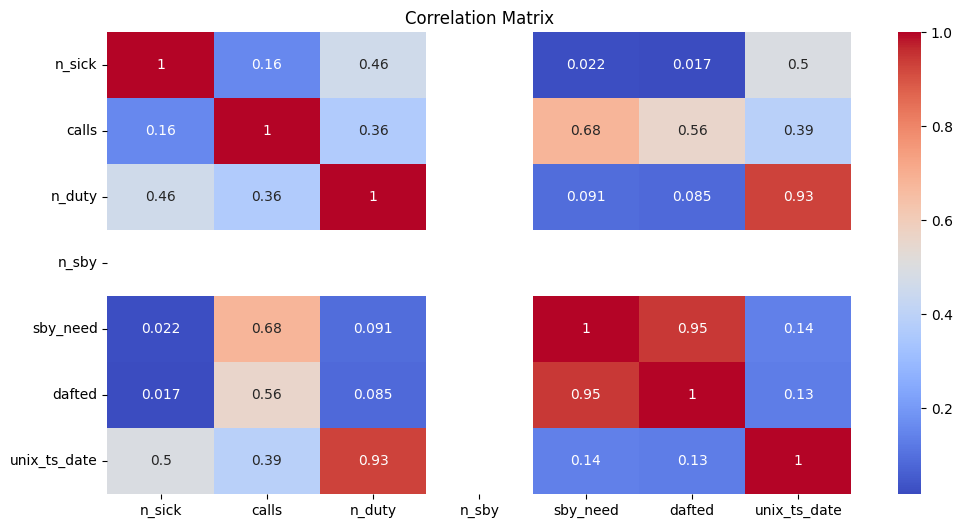

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# Plot all columns over time

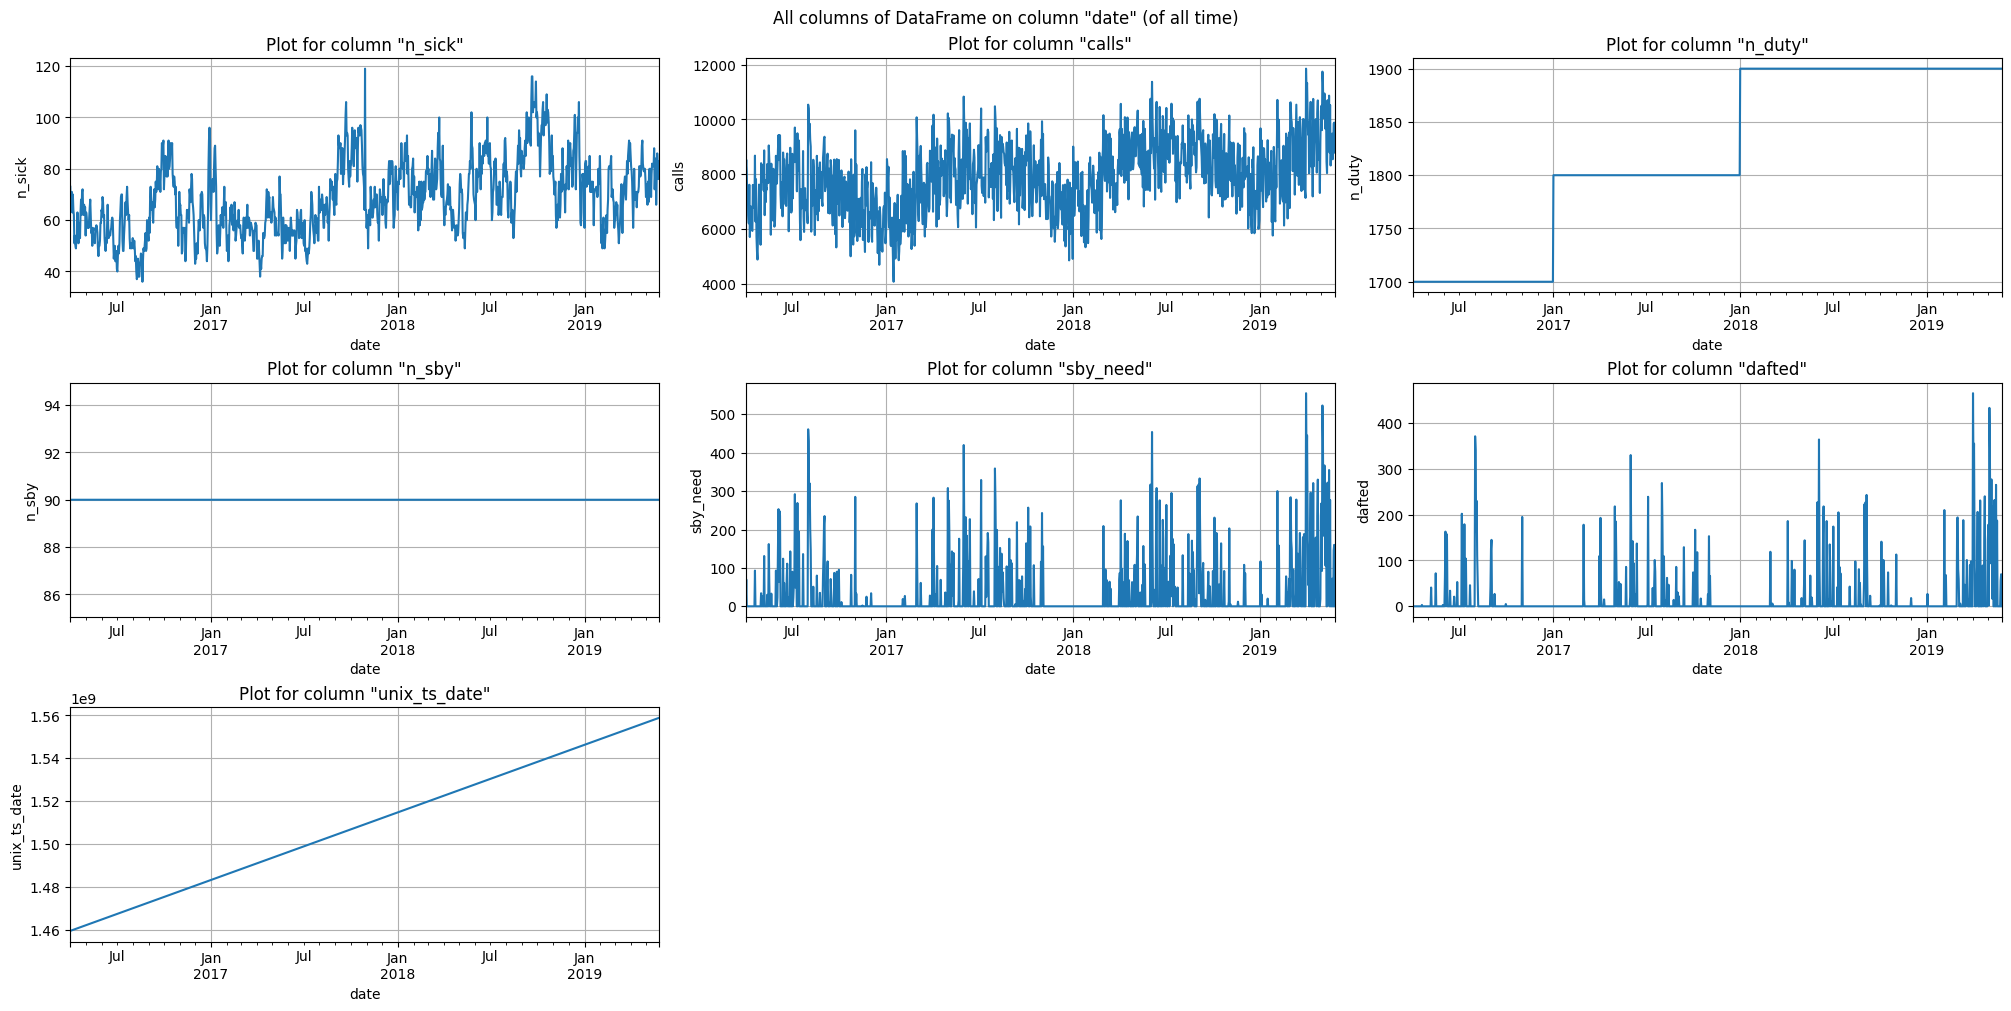

In [5]:
import math
from typing import List, Optional

def plot_columns_on_index_in_subplots(df : pd.DataFrame, columns: Optional[List[str]] = None, annotation: str = "") -> None:

    if columns is None:
        columns = df.columns

    # number of columns in datafram
    num_columns = len(columns)

    # number of rows and columns for the subplots
    if num_columns > 2:
        num_rows = math.ceil(math.sqrt(num_columns))
        num_cols = math.ceil(num_columns / num_rows)
    else:
        num_rows = 1
        num_cols = num_columns

    # Create subplots
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, 10), constrained_layout=True)
    fig.suptitle(f'All columns of DataFrame on column "{df.index.name}"' + (f" ({annotation})" if annotation else ""), fontsize=12)

    # Plots für jede Spalte erstellen
    for i, column in enumerate(columns):
        if num_columns > 2:
            row = i // num_cols
            col = i % num_cols
            ax = axes[row, col]
        else:
            ax = axes[i] if num_columns > 1 else axes
        if df[column].dtype == bool:
            df[column].astype(int).plot(ax=ax, title=f'Plot for column "{column}" (bool)')
        else:
            df[column].plot(ax=ax, title=f'Plot for column "{column}"')
        ax.set_xlabel(df.index.name)
        ax.set_ylabel(column)
        ax.grid()

    # Leere Subplots entfernen
    for j in range(i + 1, num_rows * num_cols):
        fig.delaxes(axes.flatten()[j])

    plt.show()

plot_columns_on_index_in_subplots(df, annotation="of all time")

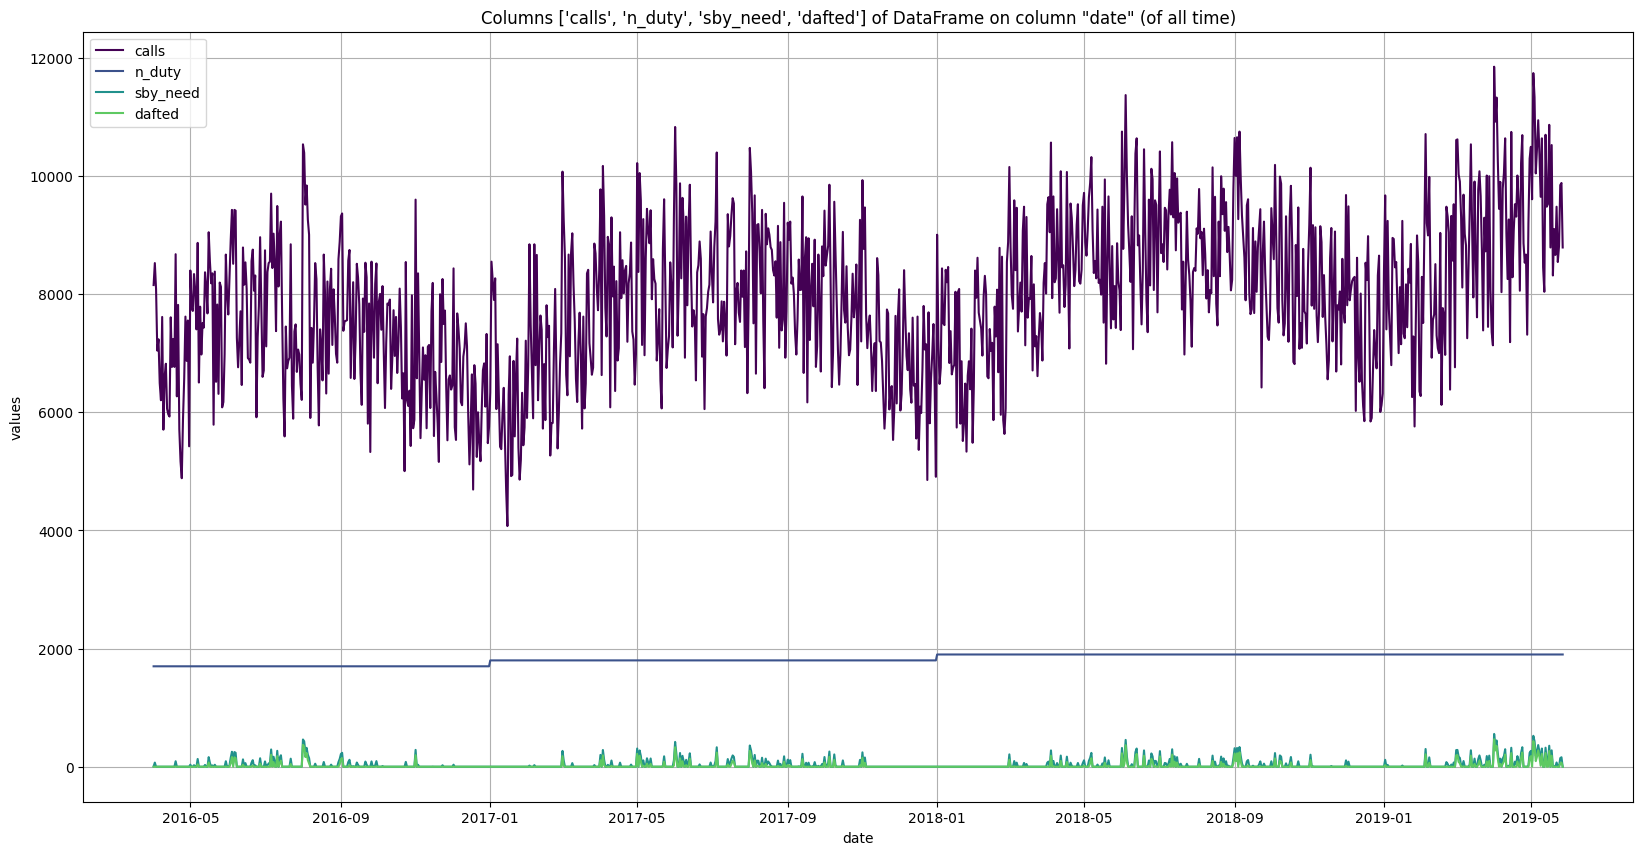

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from typing import List, Optional

def plot_columns_on_index(df: pd.DataFrame, columns: Optional[List[str]] = None, annotation: str = "") -> None:
    if columns is None:
        columns = df.columns
    
    plt.figure(figsize=(20, 10))
    
    num_columns = len(columns)
    color_map = plt.get_cmap('viridis')
    
    max_value = df[columns].select_dtypes(include=[float, int]).max().max()
    
    for i, column in enumerate(columns):
        if column in df.columns:
            color = color_map(i / num_columns)
            if df[column].dtype == bool:
                plt.plot(df.index, df[column].astype(int) * max_value, label=column + " (bool)", color=color, linestyle="dotted")
            else:
                plt.plot(df.index, df[column], label=column, color=color)
        else:
            print(f'Column "{column}" not found in DataFrame')
    
    plt.xlabel(df.index.name)
    plt.ylabel('values')
    plt.title(f'Columns {columns} of DataFrame on column "{df.index.name}"' + (f" ({annotation})" if annotation else ""))
    plt.legend()

    plt.grid()
    plt.show()

# Beispielaufruf
plot_columns_on_index(df, columns=["calls", "n_duty", "sby_need", "dafted"], annotation="of all time")


## Plot columns over one year

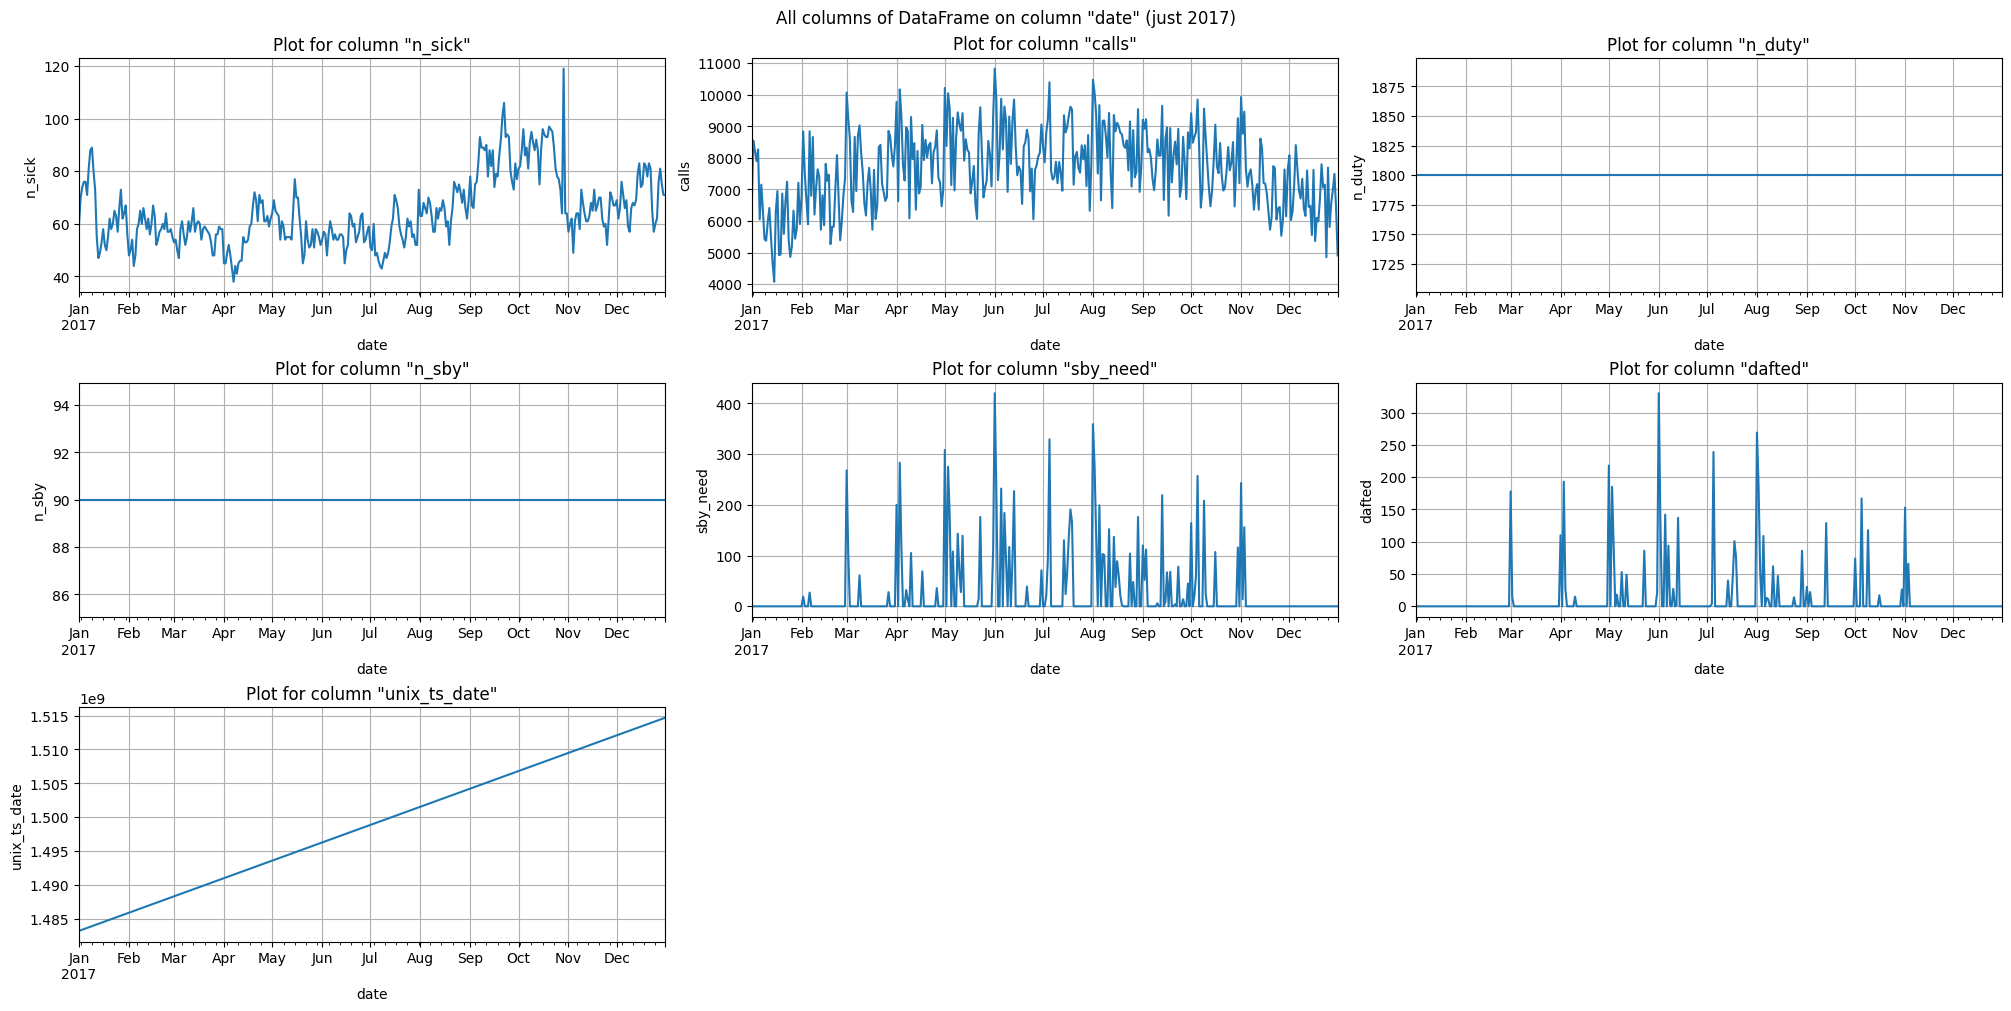

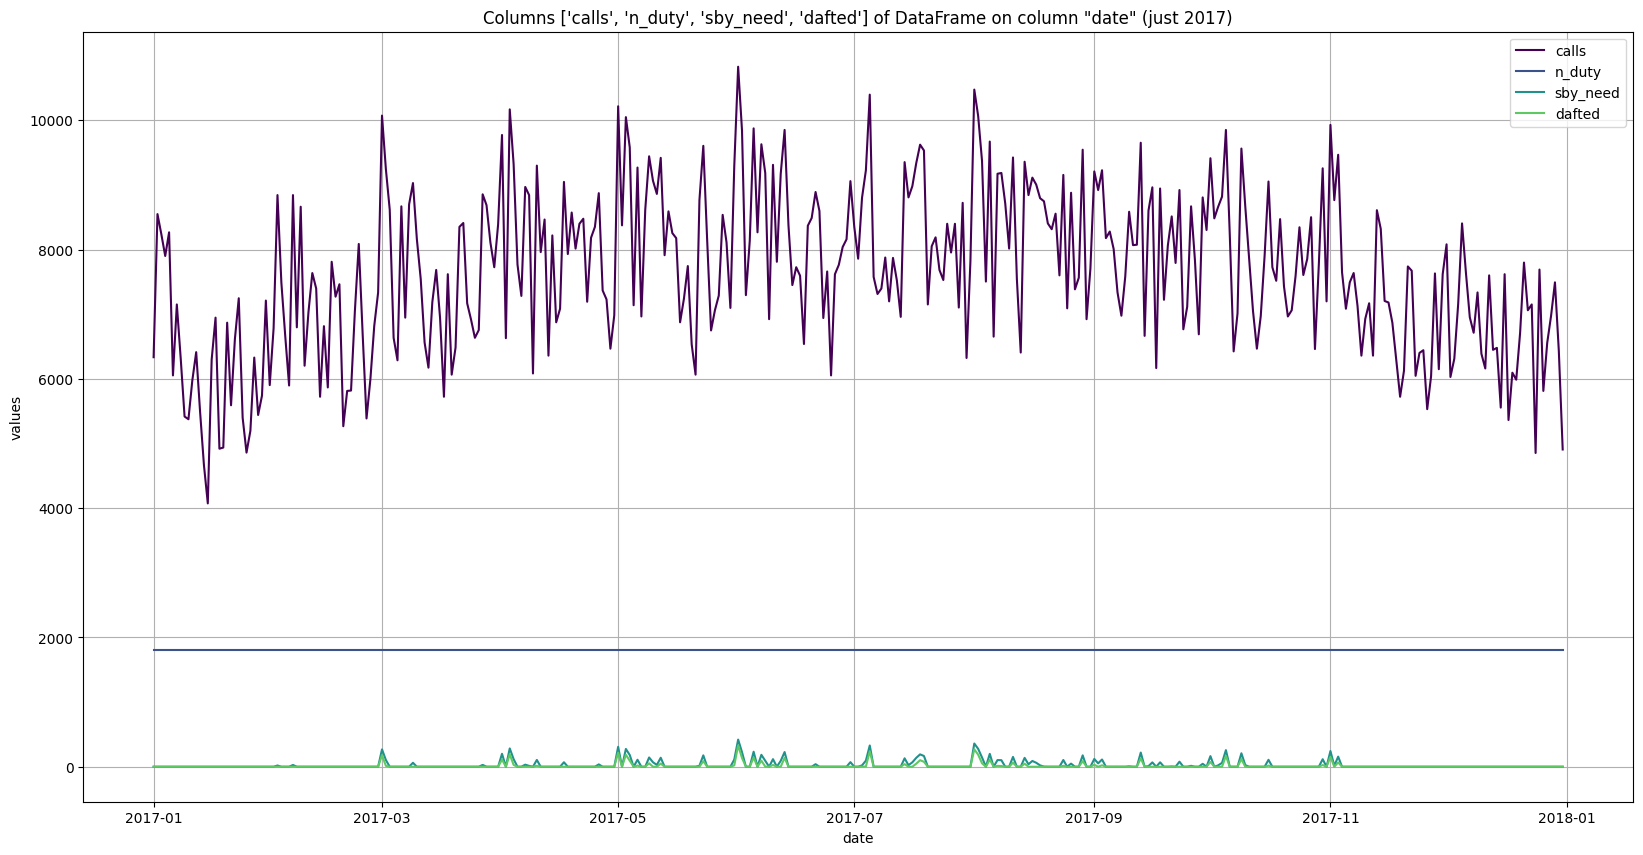

In [7]:
selected_year = 2017

one_year_df = df[df.index.year == selected_year]

plot_columns_on_index_in_subplots(one_year_df, annotation=f"just {selected_year}")
plot_columns_on_index(one_year_df, columns=["calls", "n_duty", "sby_need", "dafted"], annotation=f"just {selected_year}")

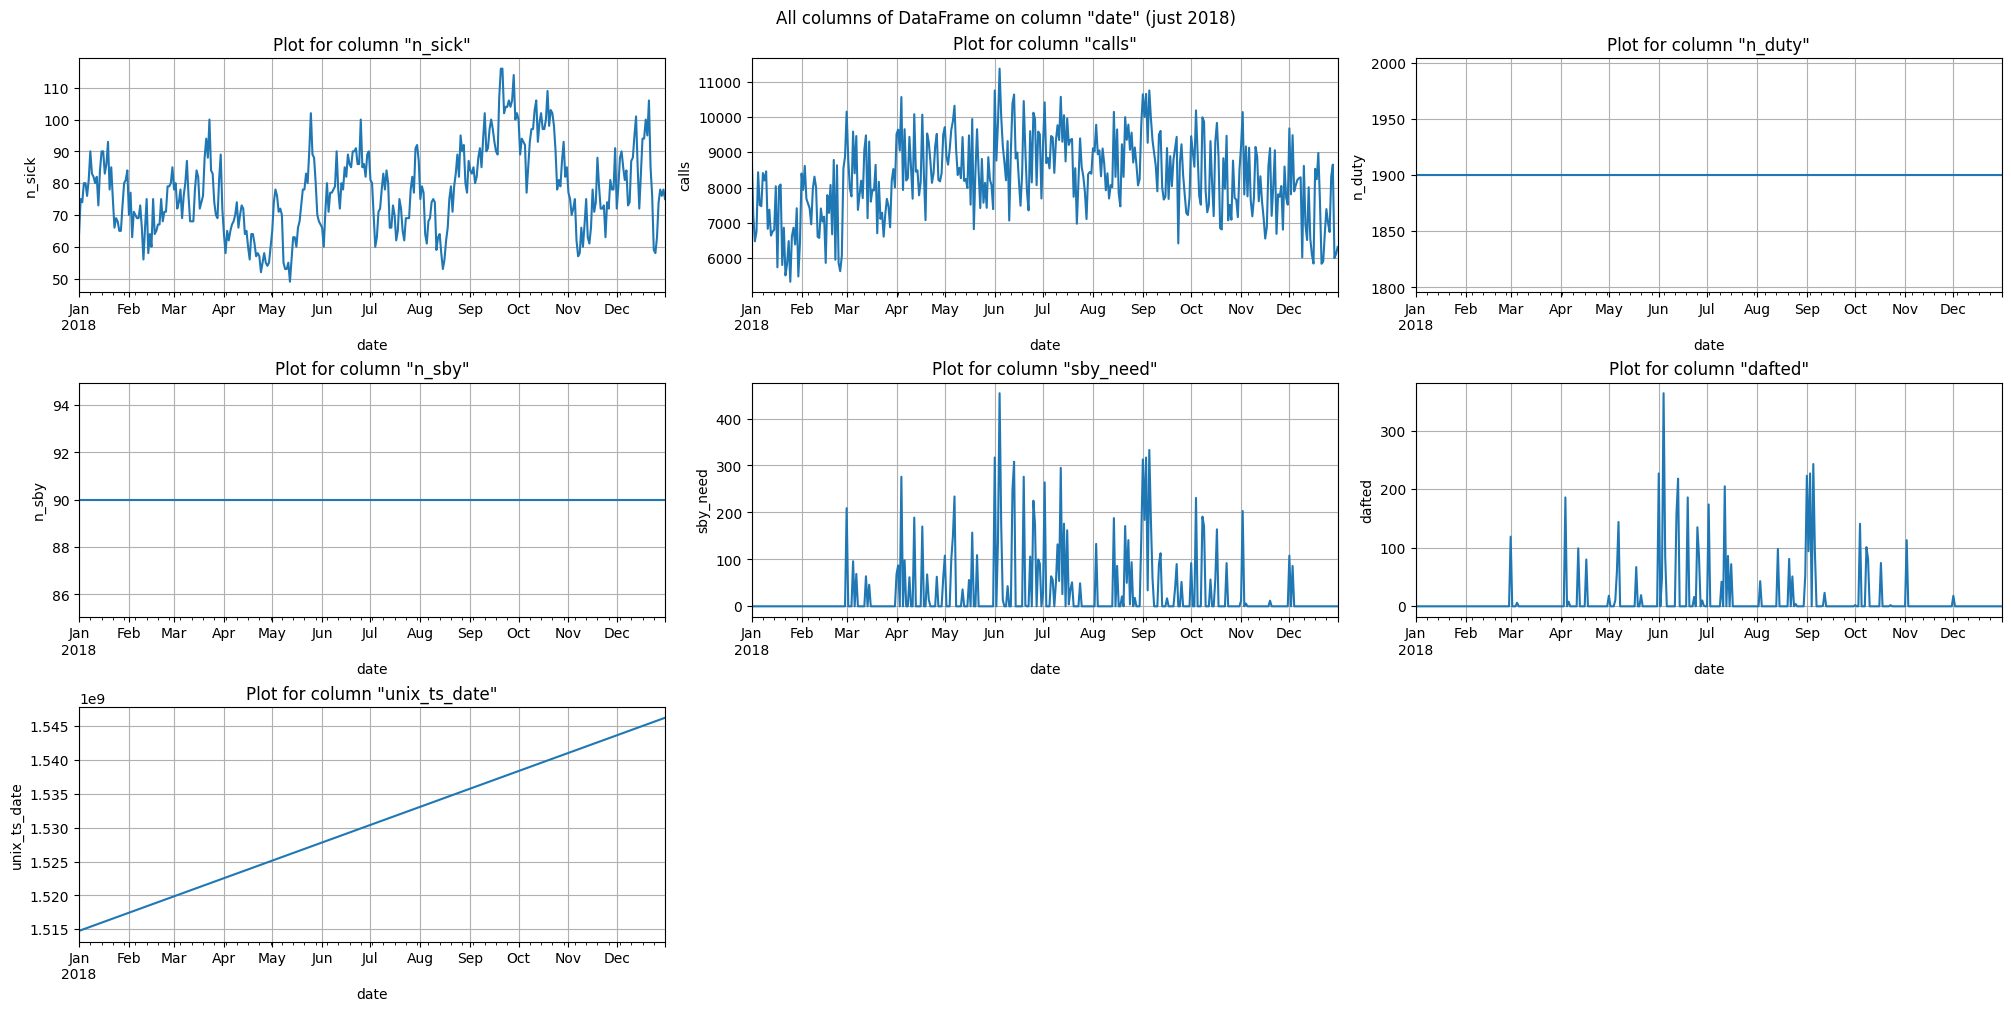

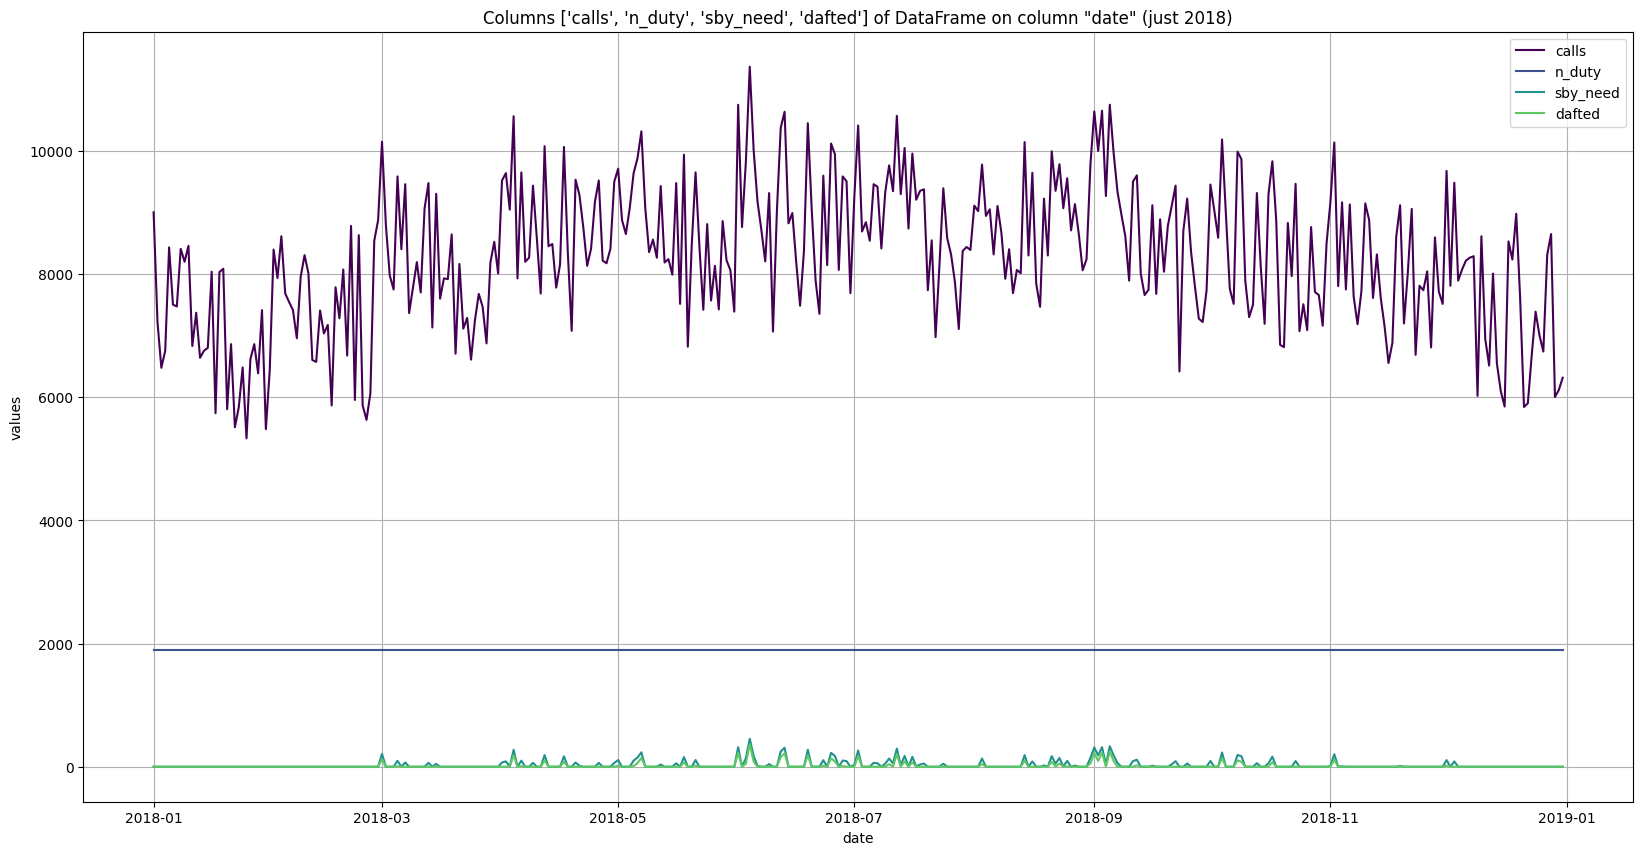

In [8]:
selected_year = 2018

one_year_df = df[df.index.year == selected_year]

plot_columns_on_index_in_subplots(one_year_df, annotation=f"just {selected_year}")
plot_columns_on_index(one_year_df, columns=["calls", "n_duty", "sby_need", "dafted"], annotation=f"just {selected_year}")

## Correlation matrix for one year

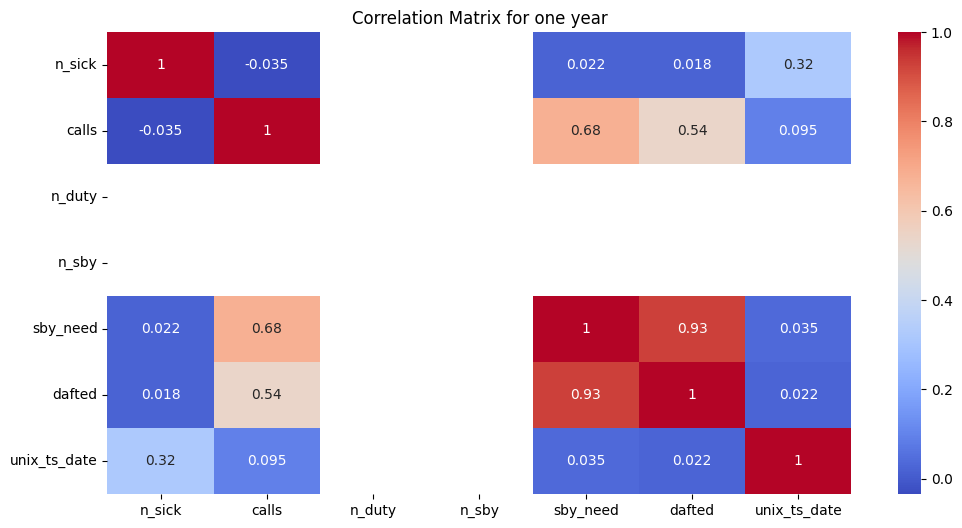

In [9]:
selected_year = 2018

one_year_df = df[df.index.year == selected_year]

plt.figure(figsize=(12, 6))
sns.heatmap(one_year_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix for one year')
plt.show()

## Findings

Erkenntnisse: 
- n_duty steigt am Anfang jeden Jahrs fix und wird nicht wieder gesenkt
- calls hat ein wiederkehrendes Muster. Es geht im Winter runter und beim Sommer hoch. Hat aber starke Ausschläge 
- ähnlich bei sby_need und logischerweise bei dafted. Im Winter nichts und sonst gelegengtlich

# Experimental data cleansing

In [10]:

correct_n_duty_and_sby_need = False

if correct_n_duty_and_sby_need:

    # Beheben von n_duty im Jahr 2019
    df.loc['2019':, 'n_duty'] += 100
    df.loc['2019':, 'sby_need'] -= 100
    df['sby_need'] = df['sby_need'].clip(lower=0)

    plot_columns_on_index_in_subplots(df, columns=["n_duty", "sby_need"], annotation=f"just {selected_year}")
    plot_columns_on_index(df, columns=["n_duty", "sby_need"], annotation=f"just {selected_year}")

# Creating new columns from current columns

In [11]:
extended_df = df.copy(deep=True)

# 
extended_df["needed_personal"] = extended_df.apply(lambda row: (row.sby_need + row.n_duty), axis=1)

extended_df["sby_used_percent"] = extended_df.apply(lambda row: (row.sby_need / row.n_sby), axis=1)

extended_df["personal_calculated_by_calls"] = extended_df.apply(lambda row: (row.calls / 4.82), axis=1) 

##############

extended_df["personal_calculated_by_calls_not_below_n_duty"] = extended_df["personal_calculated_by_calls"]

# Filter
mask = (extended_df["personal_calculated_by_calls"] < extended_df["n_duty"])

# Add offset to filtered rows
extended_df.loc[mask, 'personal_calculated_by_calls_not_below_n_duty'] = extended_df.loc[mask, 'n_duty']

############

# 
extended_df["sby_need_calculated_by_calls"] = extended_df.apply(lambda row: row.personal_calculated_by_calls_not_below_n_duty - row.n_duty, axis=1)


#
extended_df["calls_per_duty"] = extended_df.apply(lambda row: row.calls / row.n_duty, axis=1)

#
extended_df["call_stress"] = extended_df.apply(lambda row: row.calls / (row.n_duty + row.sby_need ), axis=1)

display(extended_df.describe())

,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,needed_personal,sby_used_percent,personal_calculated_by_calls,personal_calculated_by_calls_not_below_n_duty,sby_need_calculated_by_calls,calls_per_duty,call_stress
count,1152.000000,1152.000000,1152.000000,1152.0,1152.000000,1152.000000,1.152000e+03,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000
mean,68.808160,7919.531250,1820.572917,90.0,34.718750,16.335938,1.509192e+09,1855.291667,0.385764,1643.056276,1855.644882,35.071966,4.347109,4.255659
std,14.293942,1290.063571,80.086953,0.0,79.694251,53.394089,2.874511e+07,117.992747,0.885492,267.648044,118.672474,81.651972,0.663532,0.539535
min,36.000000,4074.000000,1700.000000,90.0,0.000000,0.000000,1.459469e+09,1700.000000,0.000000,845.228216,1700.000000,0.000000,2.263333,2.263333
25%,58.000000,6978.000000,1800.000000,90.0,0.000000,0.000000,1.484330e+09,1800.000000,0.000000,1447.717842,1800.000000,0.000000,3.875833,3.875833
50%,68.000000,7932.000000,1800.000000,90.0,0.000000,0.000000,1.509192e+09,1874.500000,0.000000,1645.643154,1879.045643,0.000000,4.344298,4.344298
75%,78.000000,8827.500000,1900.000000,90.0,12.250000,0.000000,1.534054e+09,1900.000000,0.136111,1831.431535,1900.000000,4.253112,4.831625,4.778991
max,119.000000,11850.000000,1900.000000,90.0,555.000000,465.000000,1.558915e+09,2455.000000,6.166667,2458.506224,2458.506224,558.506224,6.236842,4.896288


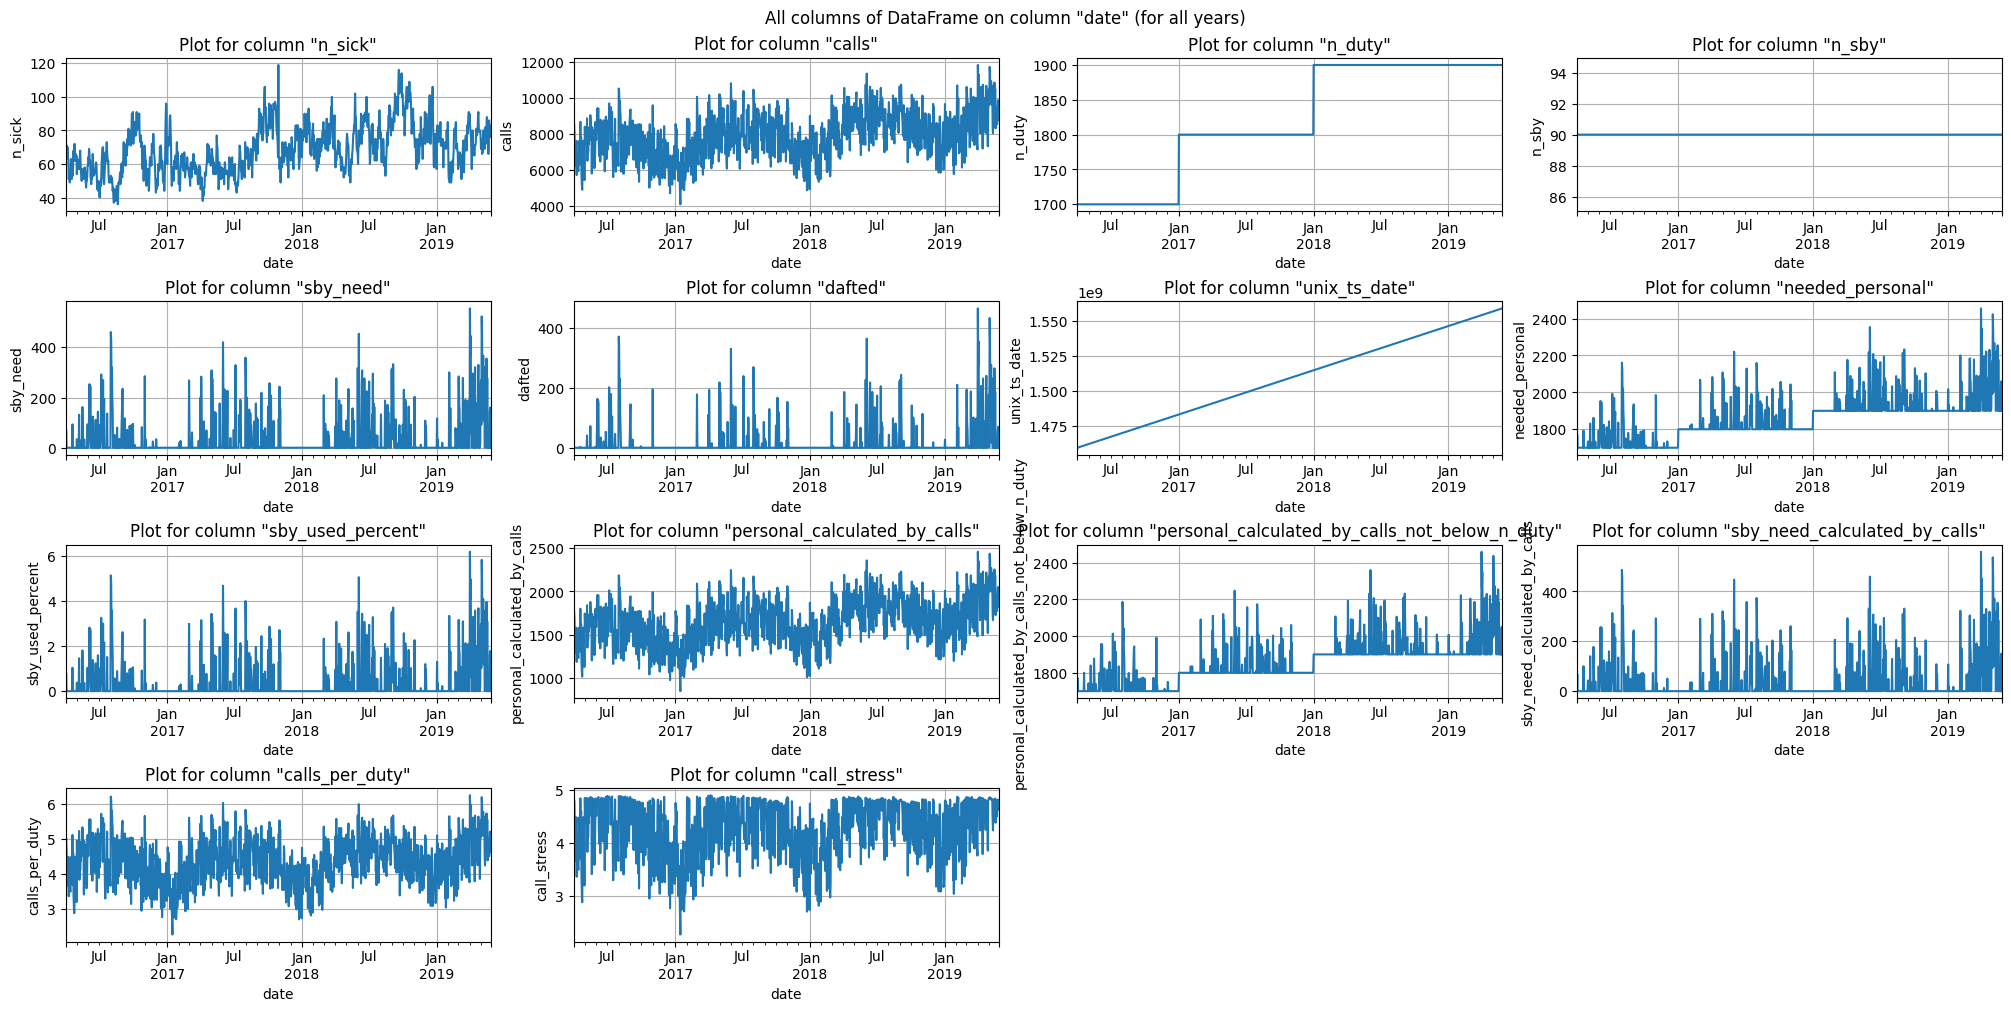

In [12]:
plot_columns_on_index_in_subplots(extended_df, annotation=f"for all years")

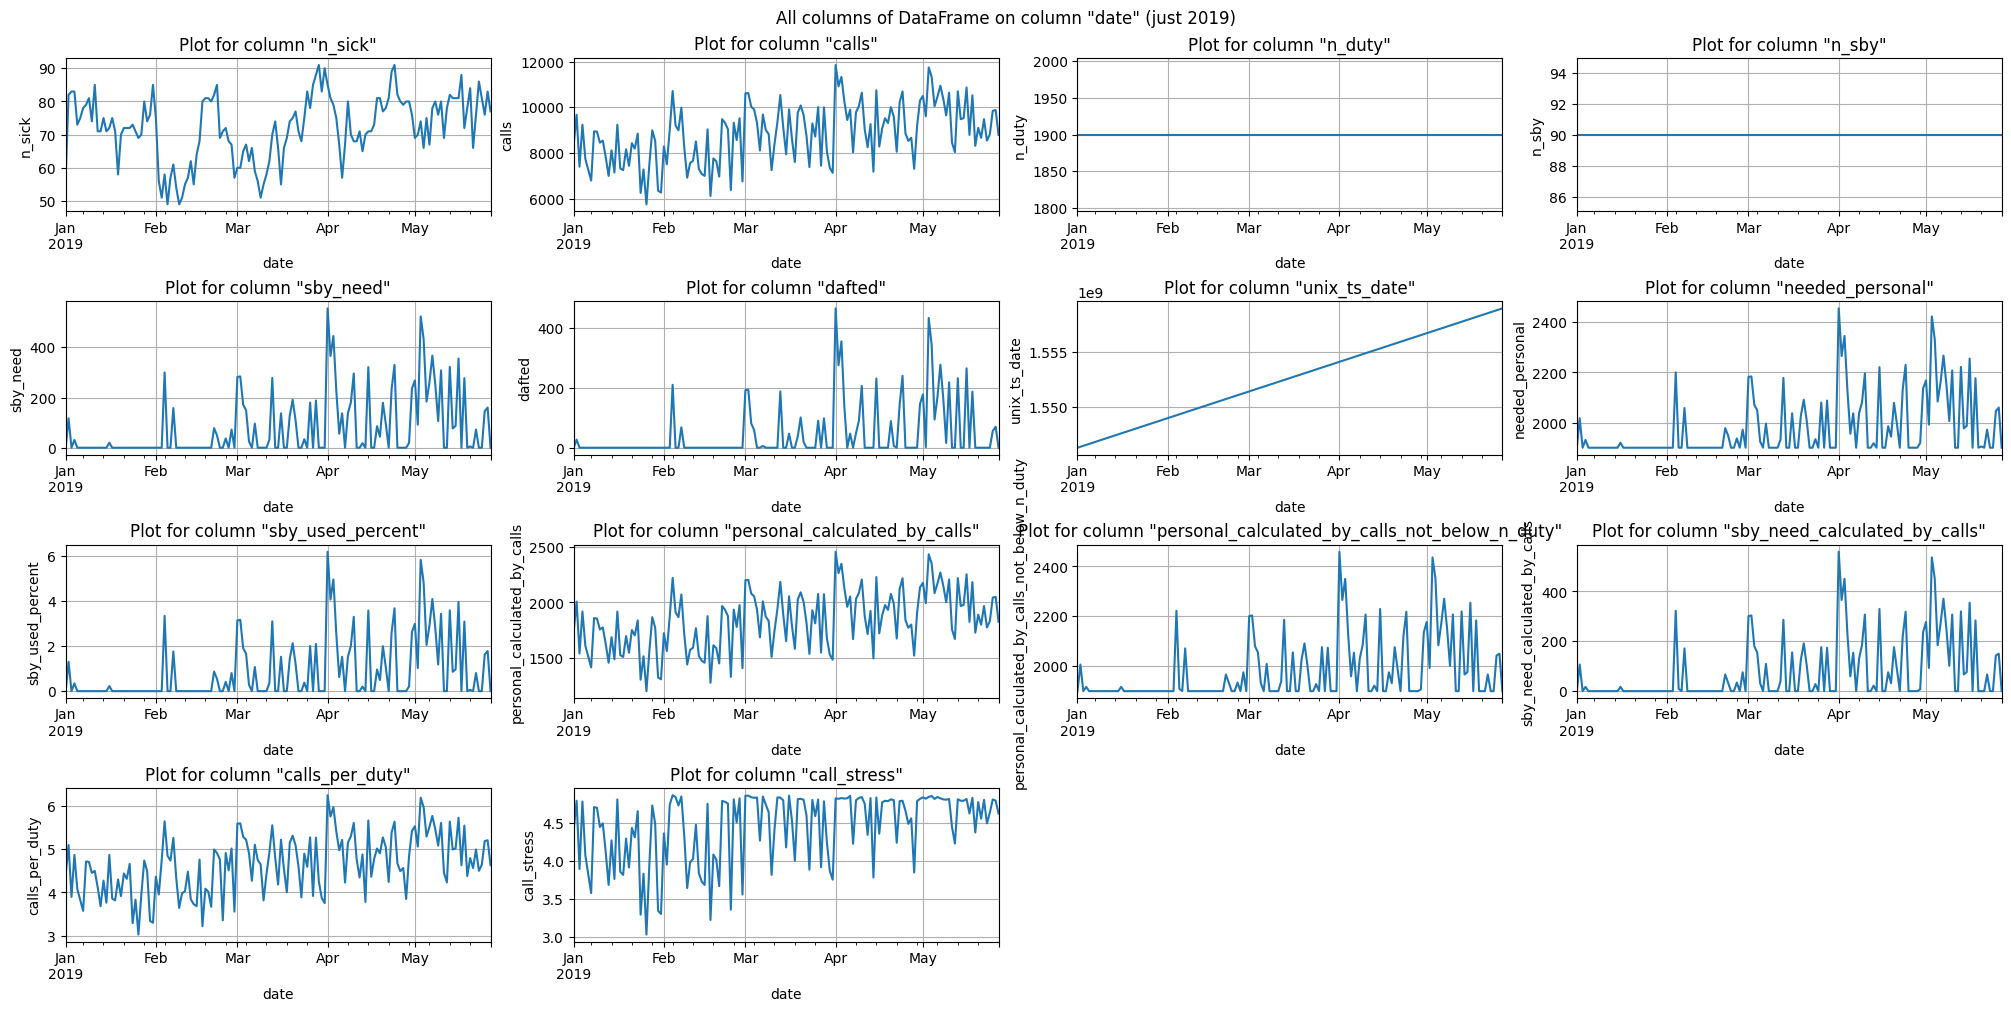

In [13]:
selected_year = 2019

one_year_df = extended_df[extended_df.index.year == selected_year]

plot_columns_on_index_in_subplots(one_year_df, annotation=f"just {selected_year}")

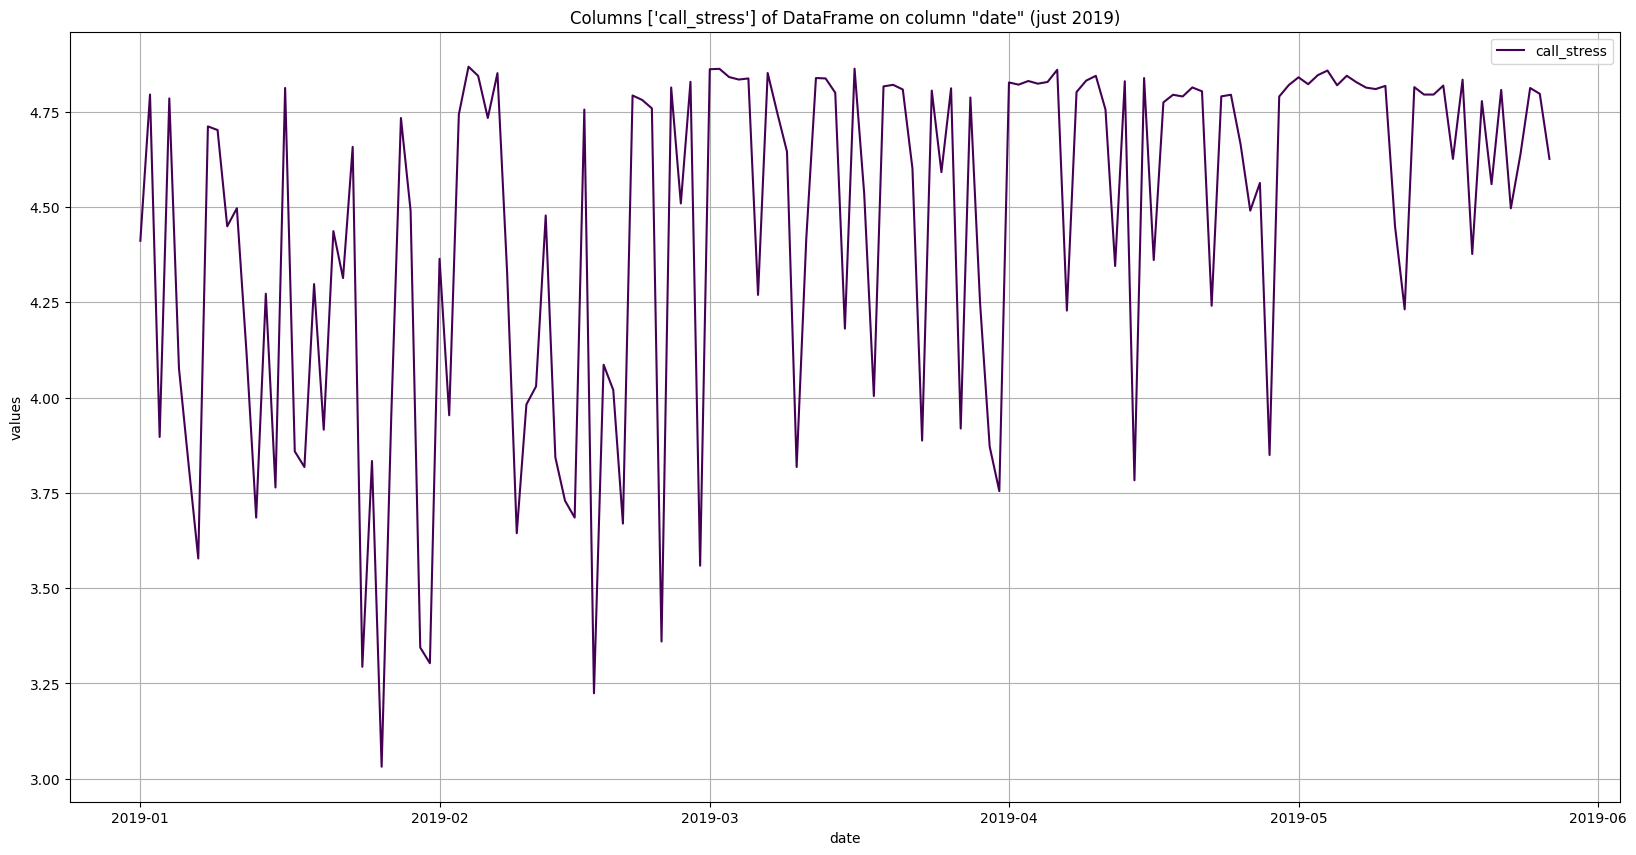

In [14]:
plot_columns_on_index(one_year_df, columns=["call_stress"], annotation=f"just {selected_year}")

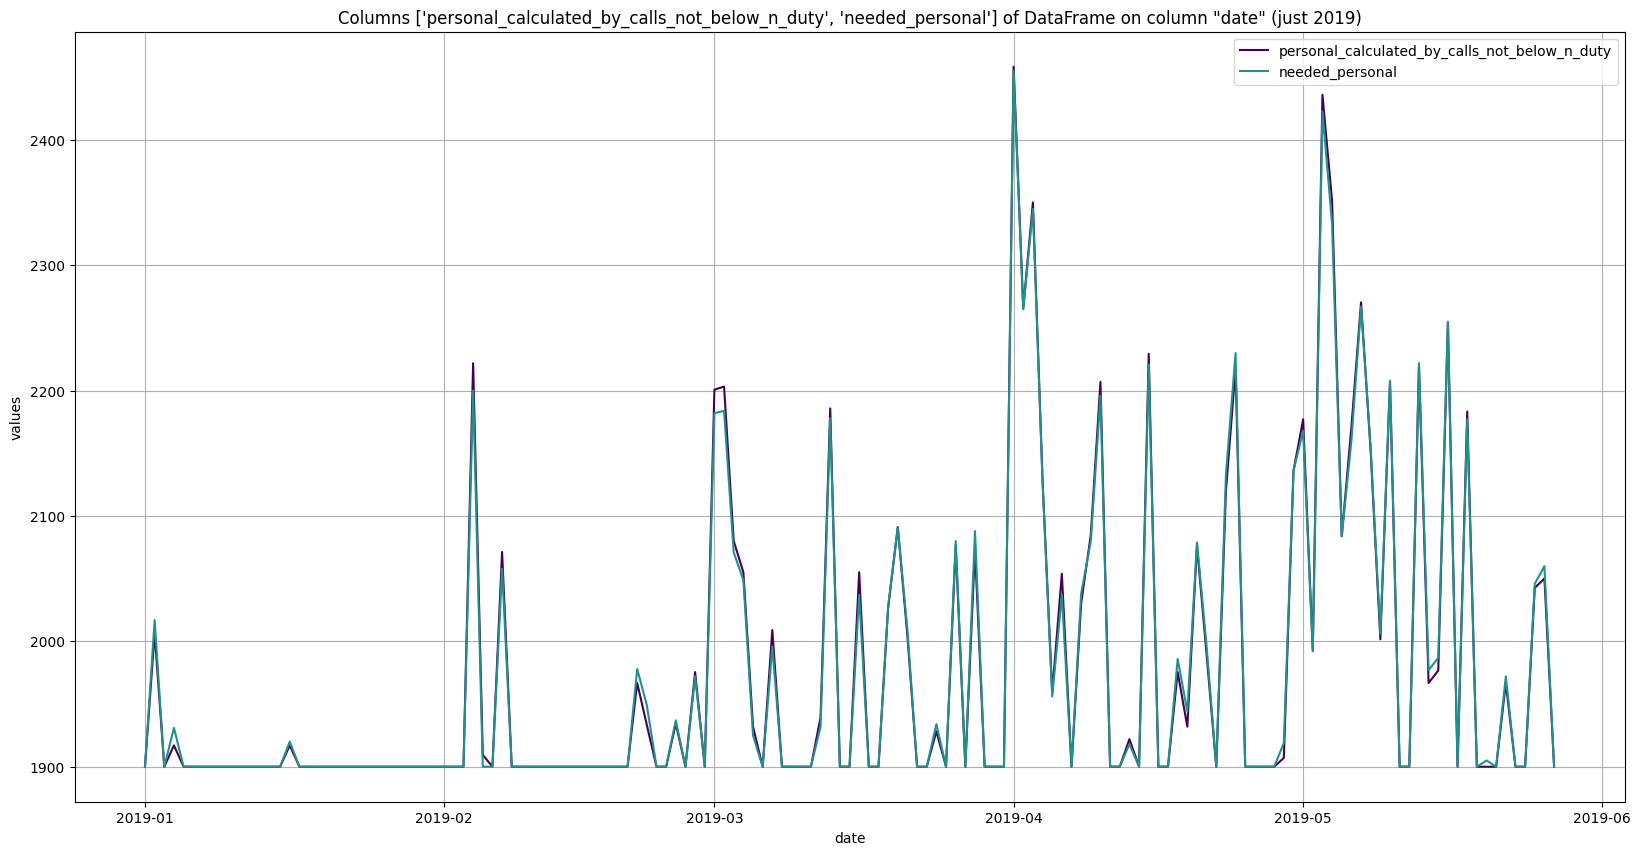

In [15]:
plot_columns_on_index(one_year_df, columns=["personal_calculated_by_calls_not_below_n_duty", "needed_personal"], annotation=f"just {selected_year}")

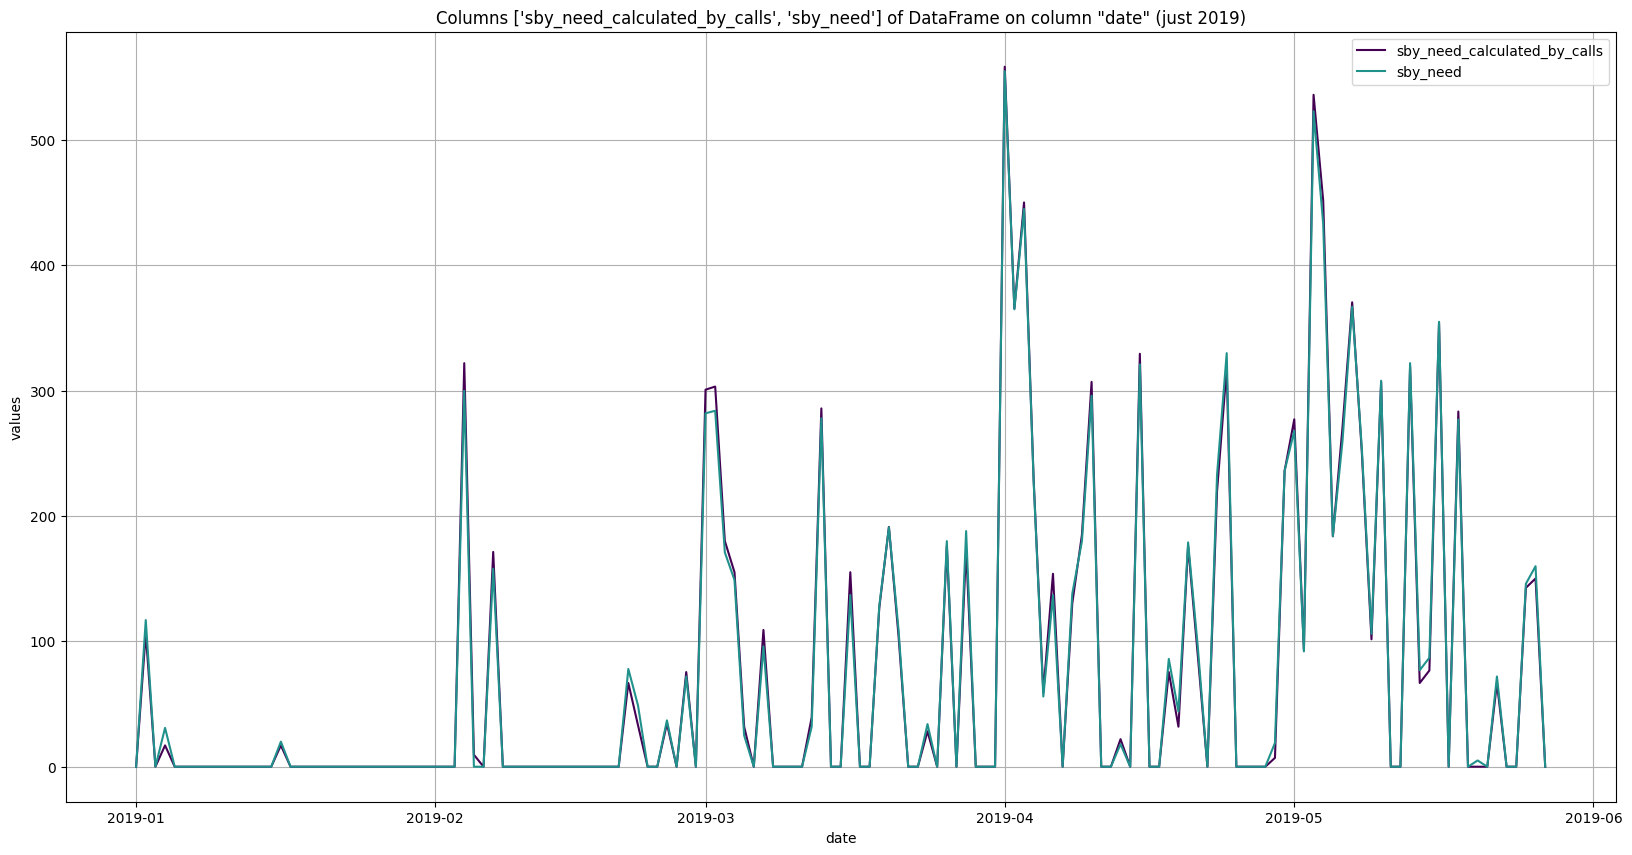

In [16]:
plot_columns_on_index(one_year_df, columns=["sby_need_calculated_by_calls", "sby_need"], annotation=f"just {selected_year}")

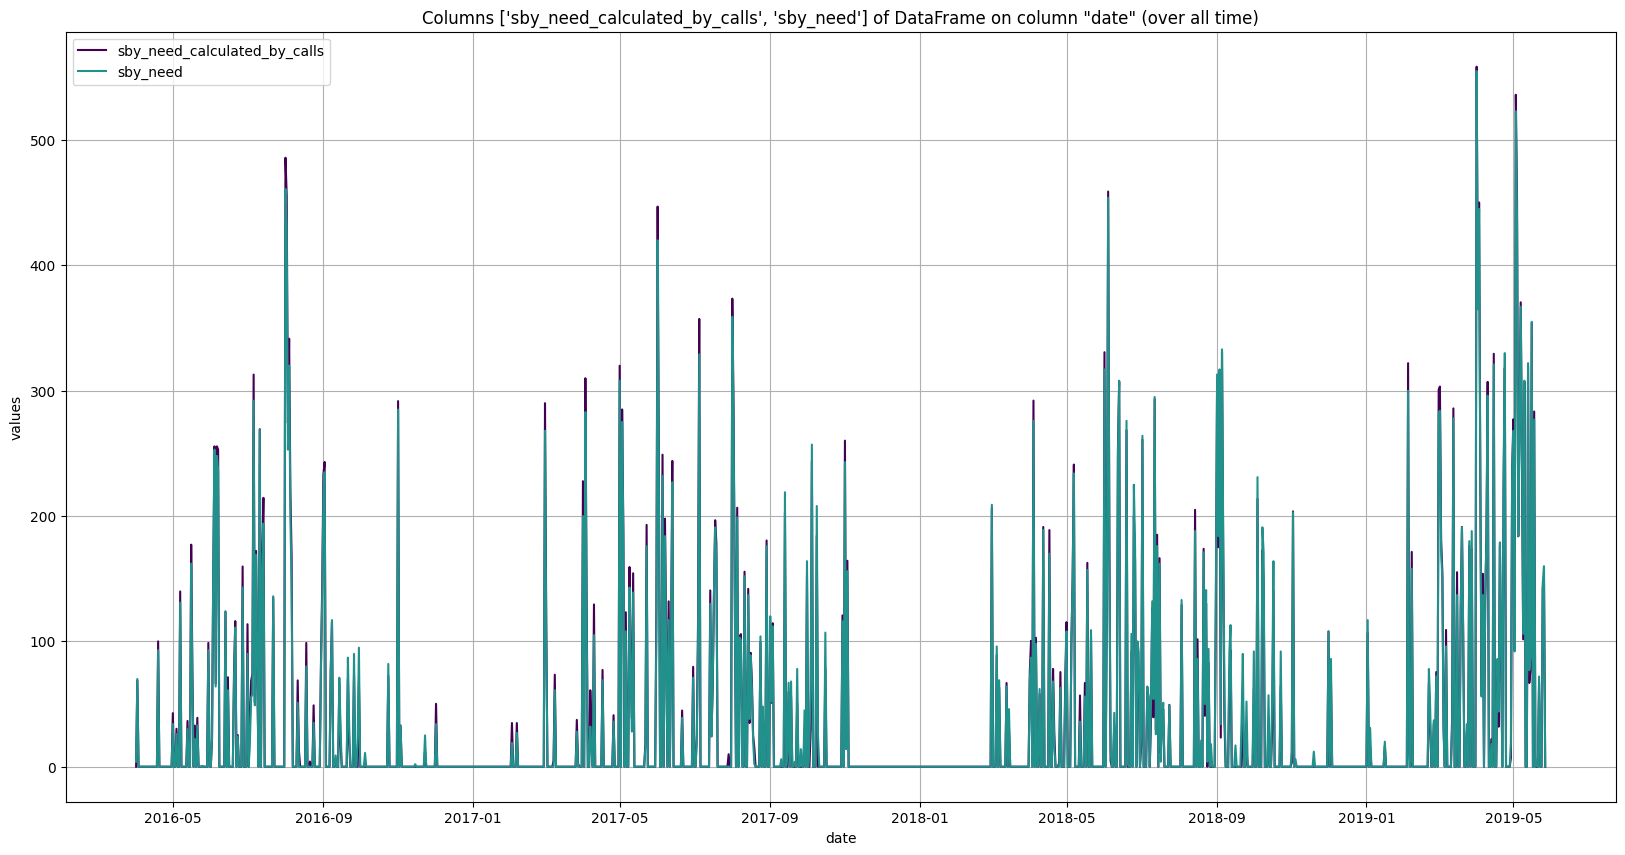

In [17]:
plot_columns_on_index(extended_df, columns=["sby_need_calculated_by_calls", "sby_need"], annotation="over all time")

## Calculate metrics

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error


def calculate_regression_metrics(y_test : List, y_pred : List, print_results : bool = False) -> dict:
    results= {
        'MAE': float(mean_absolute_error(y_test, y_pred)),
        'MSE': float(mean_squared_error(y_test, y_pred)),
        'R2':float( r2_score(y_test, y_pred)),
        'MAPE': float(mean_absolute_percentage_error(y_test, y_pred)),
    }

    if print_results:
        print(f'Results: - ' + ', '.join(f'{key}: {value}' for key, value in results.items()))

    return results

print("For needed_personal over all time:")
calculate_regression_metrics(extended_df["needed_personal"], extended_df["personal_calculated_by_calls_not_below_n_duty"], print_results=True)

print("For sby_need over all time:")
_ = calculate_regression_metrics(extended_df["sby_need"], extended_df["sby_need_calculated_by_calls"], print_results=True)

For needed_personal over all time:
Results: - MAE: 2.859411018902713, MSE: 46.34003966443395, R2: 0.9966686295485399, MAPE: 0.0014674432017933526
For sby_need over all time:
Results: - MAE: 2.859411018902713, MSE: 46.34003966443395, R2: 0.9926973654204232, MAPE: 215745573435434.72


### Custom metrics to evaluate task success

In [19]:
def calculate_custom_personal_metrics(df: pd.DataFrame, orig_column : str , pred_column : str, print_results: bool = False) -> dict:

    df = df.copy(deep=True)

    # Berechnung der Unterbesetzung und Überbesetzung
    df['understaffed'] = df[orig_column] > df[pred_column]
    df['overstaffed'] = df[orig_column] < df[pred_column]
    df['perfect'] = df[orig_column] == df[pred_column]
    
    # Anteil an Tagen mit Unterbesetzung
    total_days = len(df)
    understaffed_days = df['understaffed'].sum()
    overstaffed_days = df['overstaffed'].sum()
    perfect_days = df['perfect'].sum()
    
    # Durchschnittliche Über- und Unterbesetzung
    avg_understaffing = (df[orig_column] - df[pred_column])[df['understaffed']].mean()
    avg_overstaffing = (df[pred_column] - df[orig_column])[df['overstaffed']].mean()
    median_understaffing = (df[orig_column] - df[pred_column])[df['understaffed']].median()
    median_overstaffing = (df[pred_column] - df[orig_column])[df['overstaffed']].median()

    # Tagesdurchschnitt Ersatzfahrer für pred_column über die ganze Zeit
    avg_replacement_drivers_pred = df[pred_column].mean()
    
    # Differenz Tagesdurchschnitt Ersatzfahrer für pred_column zu Summe bei orig
    avg_replacement_drivers_orig = df[orig_column].mean()
    difference_avg_replacement_drivers = (avg_replacement_drivers_pred - avg_replacement_drivers_orig).mean()

    results = {
        'Anteil an Tagen mit Unterbesetzung (%)': understaffed_days / total_days * 100,
        'Anteil an Tagen mit Überbesetzung (%)': overstaffed_days / total_days * 100,
        'Anteil an Tagen mit perfekter Prediction (%)': perfect_days / total_days * 100,
        'Durchschnittliche Überbesetzung': avg_overstaffing,
        'Durchschnittliche Unterbesetzung': avg_understaffing,
        'Median Überbesetzung': median_overstaffing,
        'Median Unterbesetzung': median_understaffing,
        'Tagesdurchschnitt Ersatzfahrer für Planung': avg_replacement_drivers_pred,
        'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': difference_avg_replacement_drivers
    }

    if print_results:
        print(f'Results: - ' + ', '.join(f'{key}: {value}' for key, value in results.items()))

    return results

display("Aktueller Stand der Metriken mit festem n_sby:")
display(calculate_custom_personal_metrics(extended_df, "sby_need", "n_sby", print_results=False))

display("Stand, wenn man dynamisch aus Calls berechnet:")
display(calculate_custom_personal_metrics(extended_df, "sby_need", "sby_need_calculated_by_calls", print_results=False))

'Aktueller Stand der Metriken mit festem n_sby:'

{'Anteil an Tagen mit Unterbesetzung (%)': 14.84375,
 'Anteil an Tagen mit Überbesetzung (%)': 84.89583333333334,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.26041666666666663,
 'Durchschnittliche Überbesetzung': 84.35889570552148,
 'Durchschnittliche Unterbesetzung': 110.05263157894737,
 'Median Überbesetzung': 90.0,
 'Median Unterbesetzung': 86.0,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 90.0,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': 55.28125}

'Stand, wenn man dynamisch aus Calls berechnet:'

{'Anteil an Tagen mit Unterbesetzung (%)': 11.71875,
 'Anteil an Tagen mit Überbesetzung (%)': 15.364583333333334,
 'Anteil an Tagen mit perfekter Prediction (%)': 72.91666666666666,
 'Durchschnittliche Überbesetzung': 10.454649881613687,
 'Durchschnittliche Unterbesetzung': 10.693099738742982,
 'Median Überbesetzung': 9.082987551867063,
 'Median Unterbesetzung': 9.336099585062357,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 35.07196576763483,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': 0.3532157676348291}

## Findings

Erkenntnisse:
- das benötigte Personal bzw die Einsatzfahrer im Bereitschaftsdienst kann man problemlos über calls berechnen und das mit einem guten R2-Score

To-Do:
- wie bekommt man calls gut predcitet

# Plot calls

## Plot over years

In [20]:
yearly_df = df.copy(deep=True)

target_column_name = "calls"

range_of_years = range(yearly_df.index.year.min(), yearly_df.index.year.max() + 1)

# New column for each year
for year in range_of_years:
    yearly_df[f'year_{year}'] = yearly_df.apply(lambda row: row[target_column_name] if row.name.year == year else None, axis=1)

# Only select yearly columns
yearly_df = yearly_df[[f'year_{year}' for year in range_of_years]]

yearly_df.index = yearly_df.index.day_of_year

display(yearly_df)
display(yearly_df.describe())

,year_2016,year_2017,year_2018,year_2019
date,,,,
92,8154.0,NaN,NaN,NaN
93,8526.0,NaN,NaN,NaN
94,8088.0,NaN,NaN,NaN
95,7044.0,NaN,NaN,NaN
96,7236.0,NaN,NaN,NaN
...,...,...,...,...
143,NaN,NaN,NaN,8544.0
144,NaN,NaN,NaN,8814.0
145,NaN,NaN,NaN,9846.0


,year_2016,year_2017,year_2018,year_2019
count,275.000000,365.000000,365.000000,147.000000
mean,7306.472727,7656.953425,8274.032877,8838.163265
std,1124.147688,1229.558677,1147.060667,1286.484080
min,4692.000000,4074.000000,5334.000000,5760.000000
25%,6492.000000,6816.000000,7518.000000,7884.000000
50%,7272.000000,7638.000000,8268.000000,8934.000000
75%,8157.000000,8592.000000,9120.000000,9777.000000
max,10536.000000,10830.000000,11370.000000,11850.000000


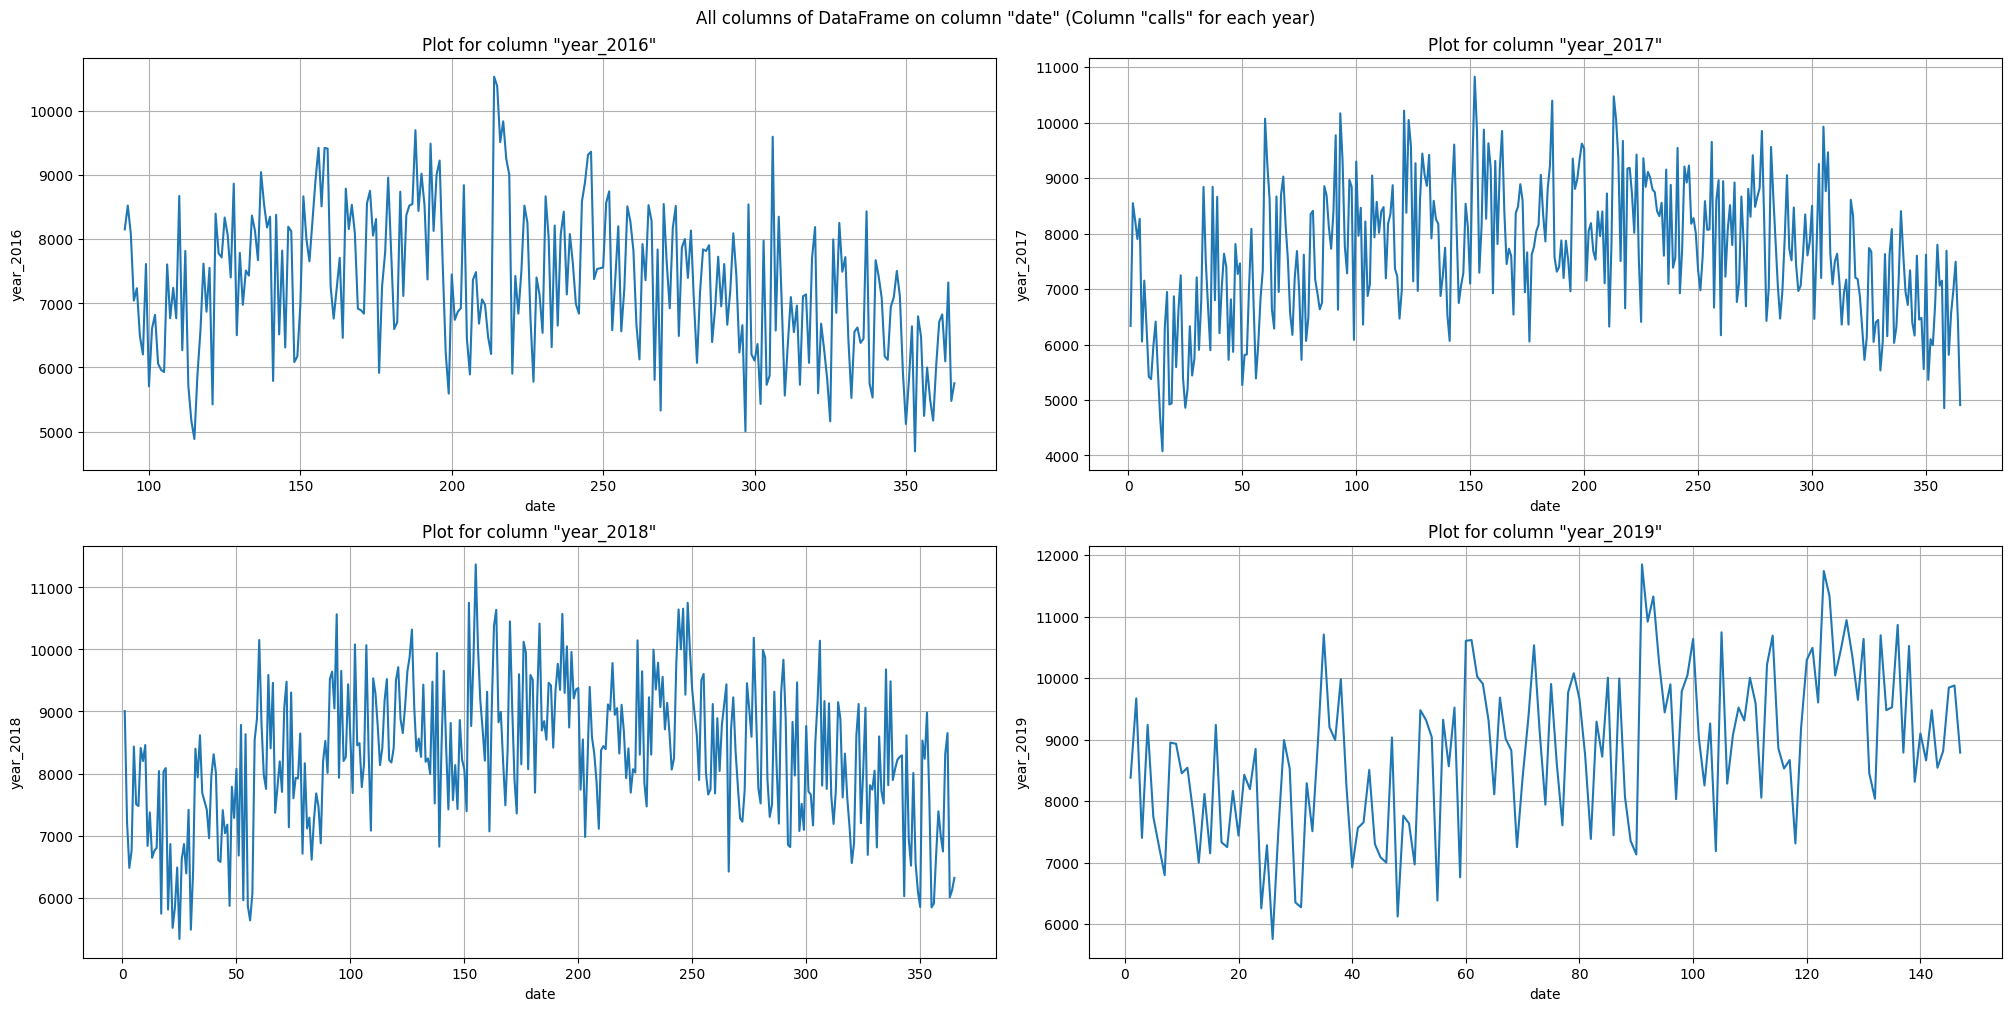

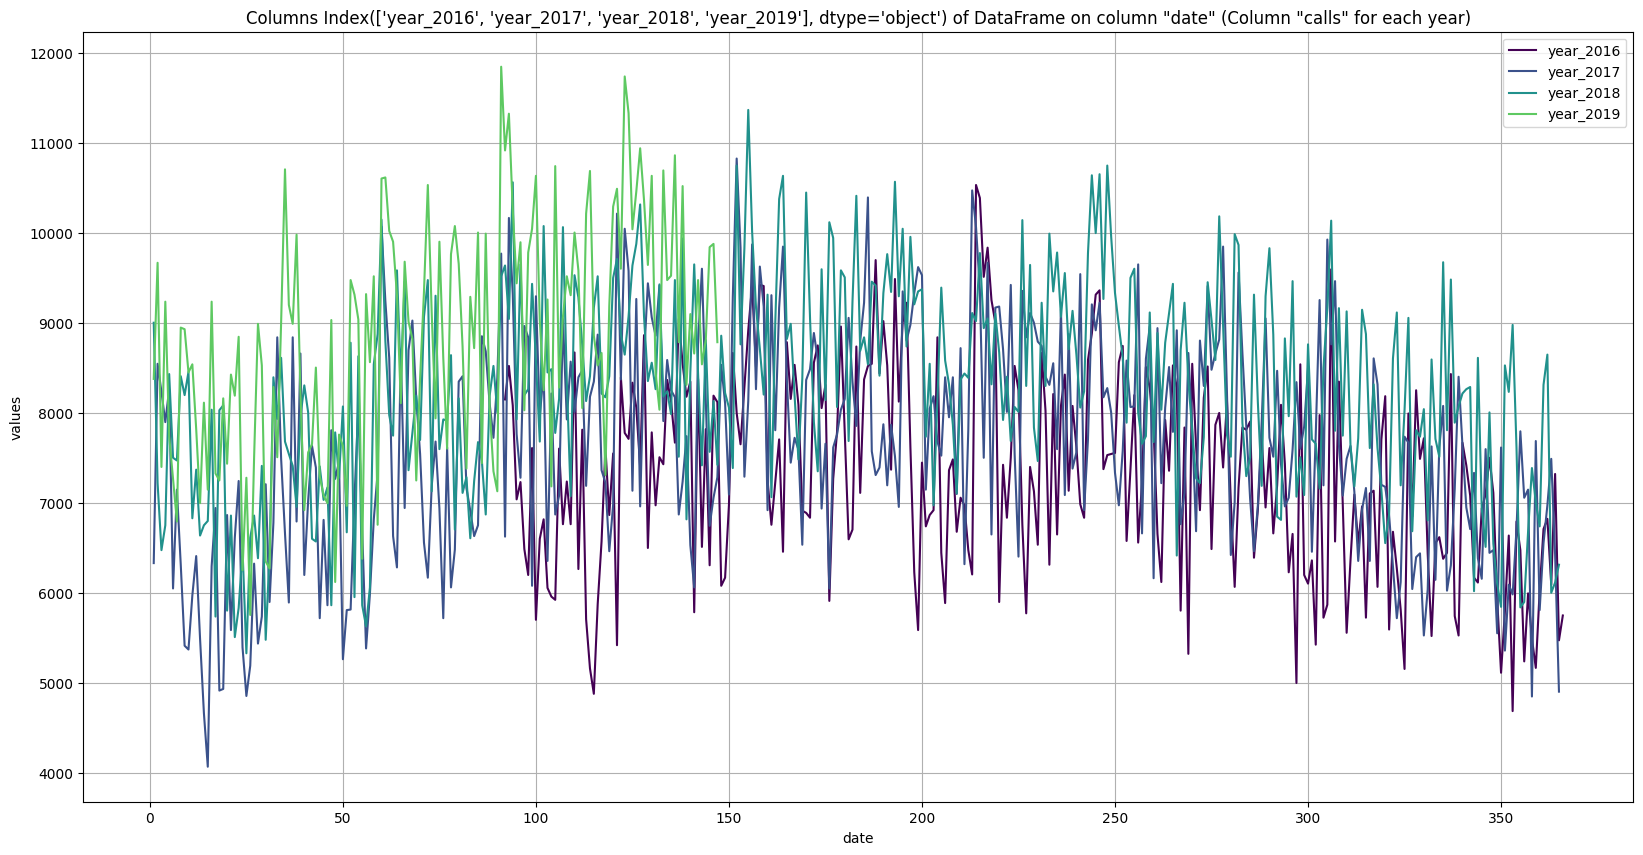

In [21]:
plot_columns_on_index_in_subplots(yearly_df, annotation=f'Column "{target_column_name}" for each year')
plot_columns_on_index(yearly_df, annotation=f'Column "{target_column_name}" for each year')

## Plot over months

In [22]:
selected_year = 2017

monthly_df = df.copy(deep=True)[df.index.year == selected_year]

target_column_name = "calls"


# New column for each month 
for month in range(1, 13):
    monthly_df[f'month_{month}'] = monthly_df.apply(lambda row: row[target_column_name] if row.name.month == month else None, axis=1)

# Only select monthly columns
monthly_df = monthly_df[[f'month_{month}' for month in range(1, 13)]]

monthly_df.index = monthly_df.index.day

display(monthly_df)
display(monthly_df.describe())

,month_1,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
date,,,,,,,,,,,,
1,6336.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,8550.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,8238.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7902.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,8268.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
27,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6558.0
28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6978.0
29,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7494.0


,month_1,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
count,31.000000,28.000000,31.000000,30.000000,31.000000,30.000000,31.000000,31.000000,30.00000,31.000000,30.000000,31.000000
mean,6185.806452,6910.928571,7625.612903,8007.400000,8228.129032,8316.000000,8172.193548,8491.161290,8072.40000,7942.451613,7186.600000,6703.354839
std,1122.510562,998.717916,1090.230363,1048.536734,1112.122887,1098.626729,929.351366,1026.315062,887.55618,942.898893,1069.598977,891.576190
min,4074.000000,5268.000000,5724.000000,6084.000000,6066.000000,6054.000000,6324.000000,6408.000000,6168.00000,6426.000000,5532.000000,4854.000000
25%,5409.000000,5970.000000,6696.000000,7203.000000,7191.000000,7630.500000,7527.000000,7584.000000,7399.50000,7131.000000,6360.000000,6129.000000
50%,6054.000000,6819.000000,7620.000000,8100.000000,8256.000000,8214.000000,7956.000000,8748.000000,8127.00000,7854.000000,7149.000000,6714.000000
75%,6909.000000,7471.500000,8514.000000,8776.500000,9168.000000,9145.500000,8805.000000,9180.000000,8773.50000,8583.000000,7647.000000,7416.000000
max,8550.000000,8844.000000,10074.000000,10170.000000,10218.000000,10830.000000,10398.000000,10476.000000,9654.00000,9852.000000,9930.000000,8406.000000


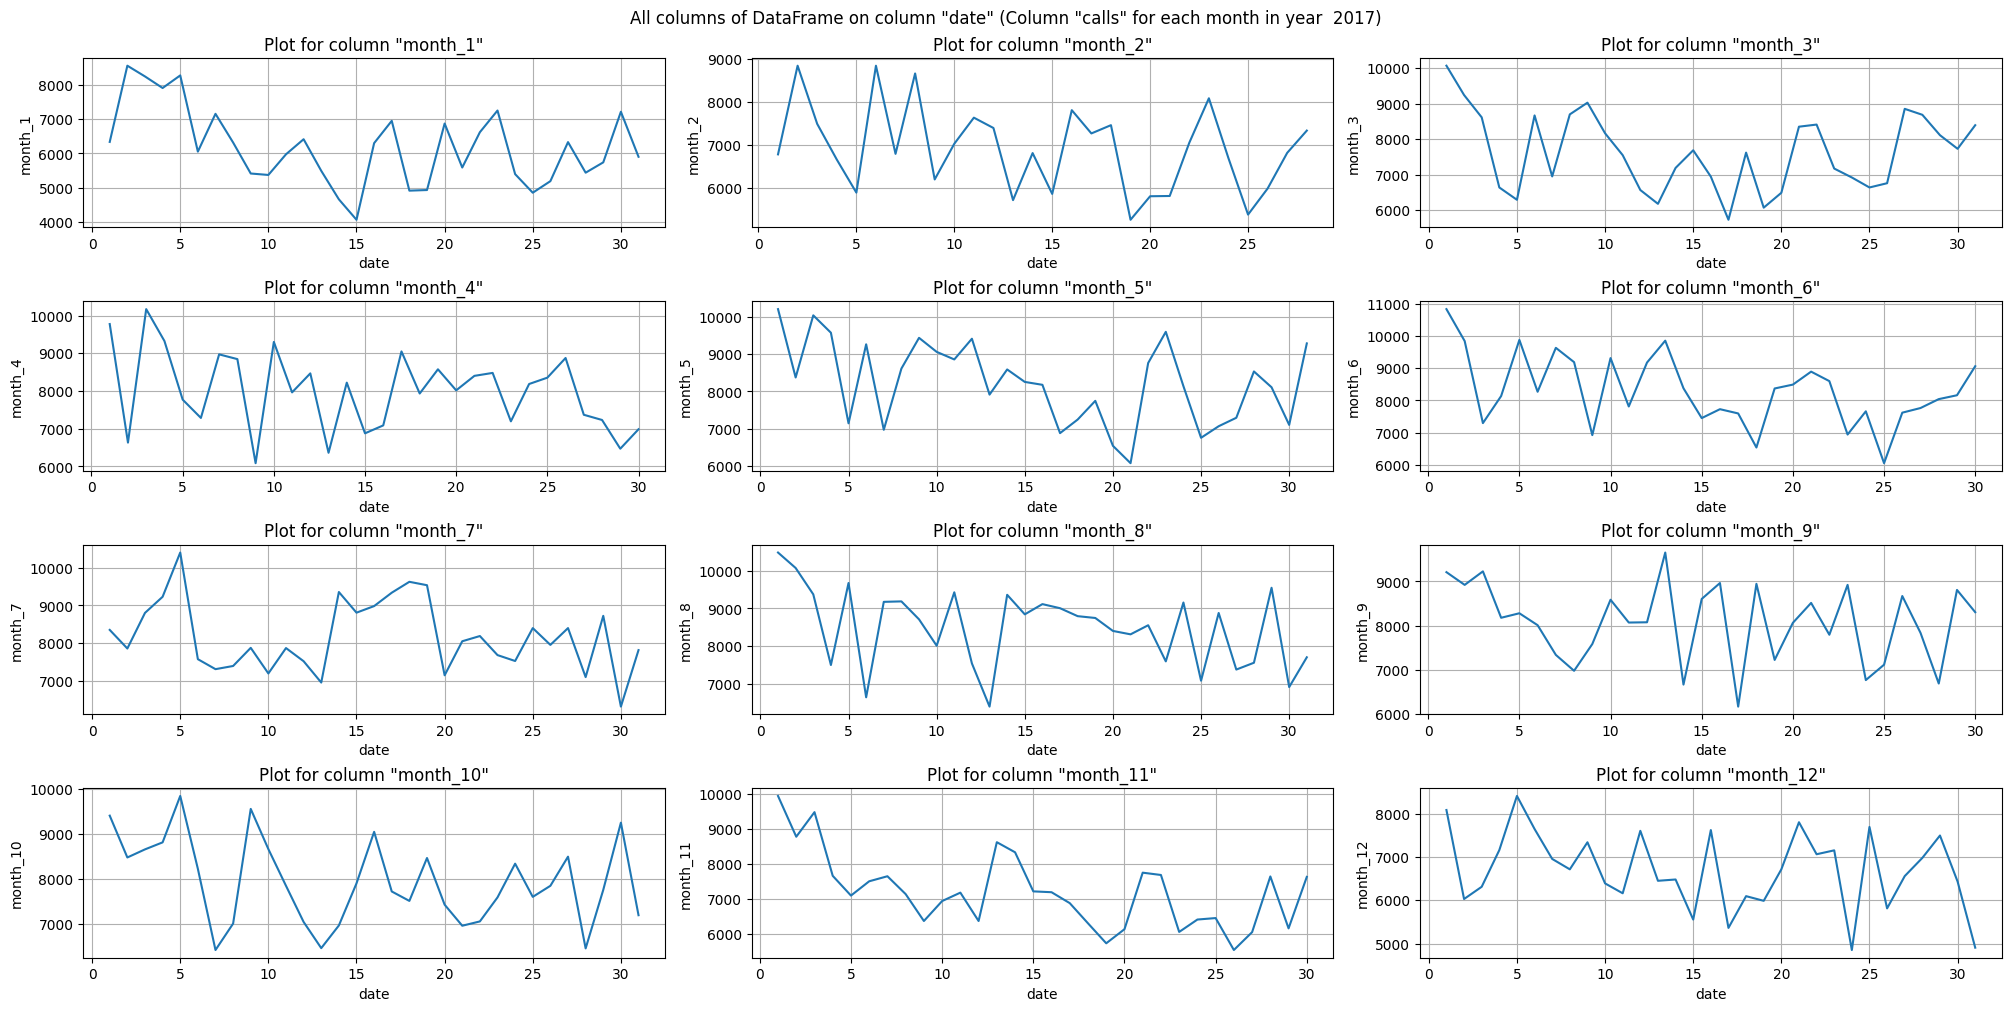

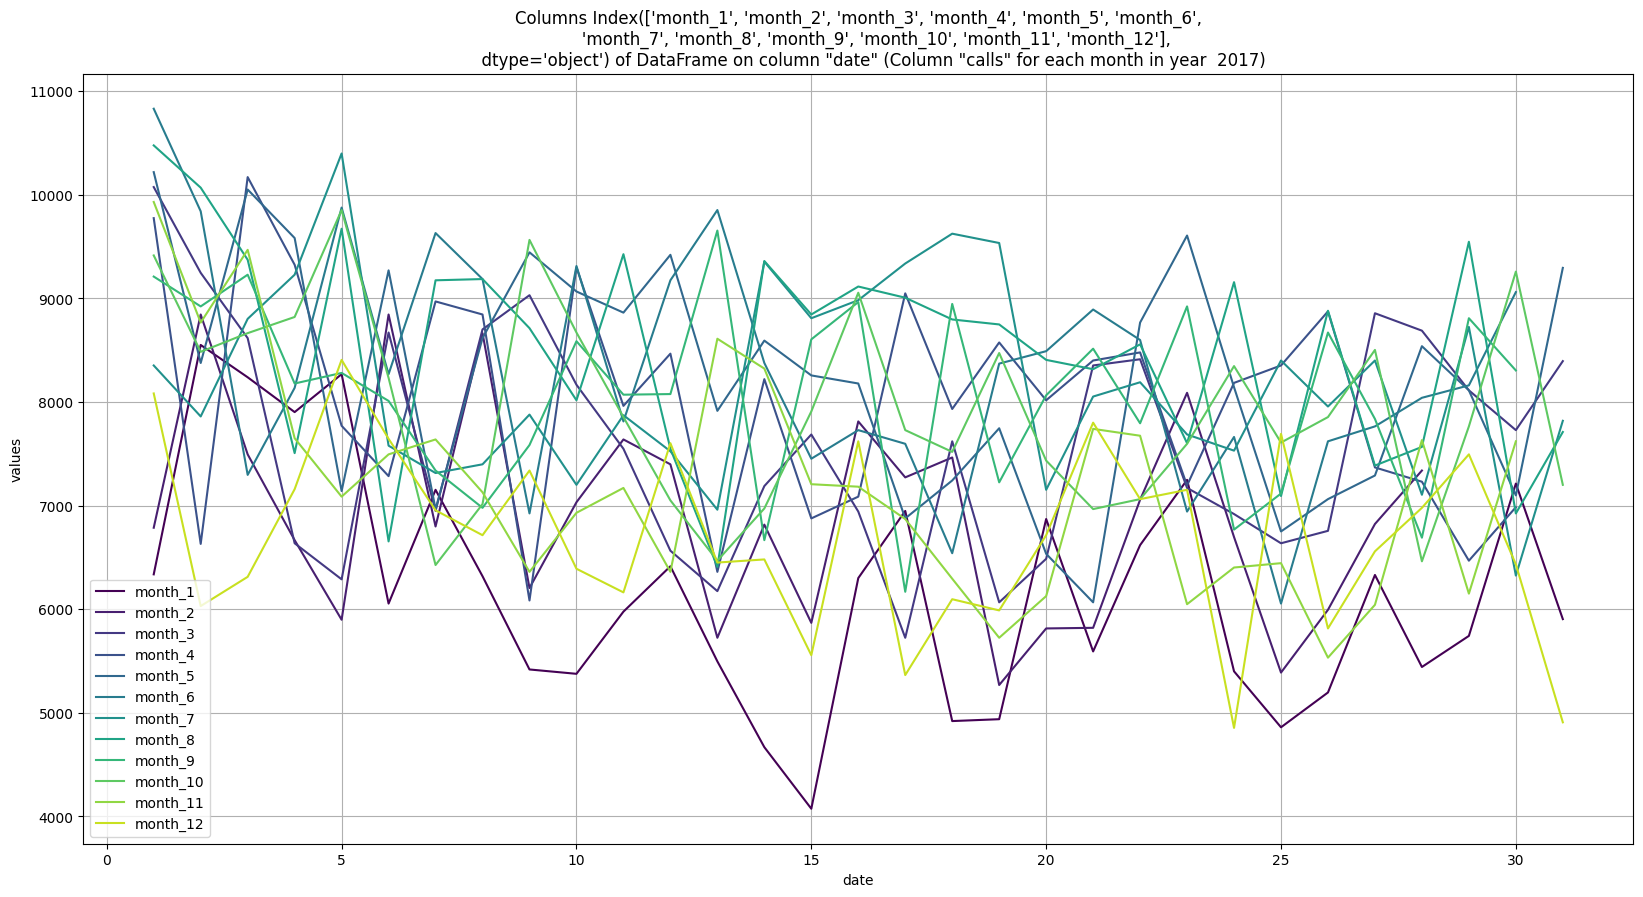

In [23]:
plot_columns_on_index_in_subplots(monthly_df, annotation=f'Column "{target_column_name}" for each month in year  {selected_year}')
plot_columns_on_index(monthly_df, annotation=f'Column "{target_column_name}" for each month in year  {selected_year}')

## Plot Fourier-Transformation

In [24]:
display(df)

,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date
date,,,,,,,
2016-04-01,73,8154.0,1700,90,4.0,0.0,1459468800
2016-04-02,64,8526.0,1700,90,70.0,0.0,1459555200
2016-04-03,68,8088.0,1700,90,0.0,0.0,1459641600
2016-04-04,71,7044.0,1700,90,0.0,0.0,1459728000
2016-04-05,63,7236.0,1700,90,0.0,0.0,1459814400
...,...,...,...,...,...,...,...
2019-05-23,86,8544.0,1900,90,0.0,0.0,1558569600
2019-05-24,81,8814.0,1900,90,0.0,0.0,1558656000
2019-05-25,76,9846.0,1900,90,146.0,56.0,1558742400


/tmp/ipykernel_177761/285100035.py:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  frequencies = np.fft.fftfreq(len(signal_window), d=(df[time][1] - df[time][0]))


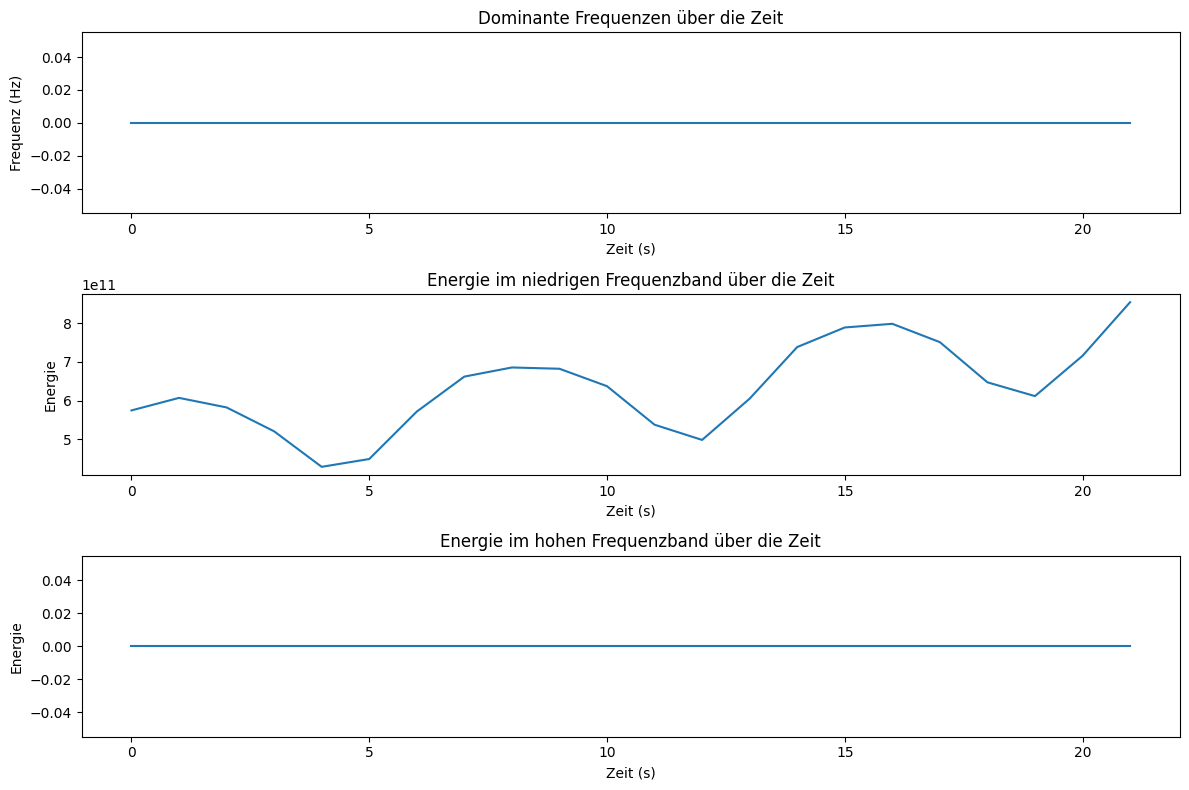

In [25]:
import numpy as np

signal = "calls"
time = "unix_ts_date"

# Fenstergröße für die Fourier-Transformation
window_size = 100
step_size = 50

# Listen für Features
dominant_frequencies_list = []
low_band_energy_list = []
high_band_energy_list = []
time_list = []

# Sliding Window Fourier-Transformation
for start in range(0, len(df) - window_size, step_size):
    end = start + window_size
    signal_window = df[signal][start:end]
    time_window = df[time][start:end].mean()
    
    fft_result = np.fft.fft(signal_window)
    frequencies = np.fft.fftfreq(len(signal_window), d=(df[time][1] - df[time][0]))
    
    # Dominante Frequenzen extrahieren
    dominant_frequencies = frequencies[np.argsort(np.abs(fft_result))[-1]]
    
    # Energie in bestimmten Frequenzbändern berechnen
    low_band_energy = np.sum(np.abs(fft_result[(frequencies >= 0) & (frequencies < 10)])**2)
    high_band_energy = np.sum(np.abs(fft_result[(frequencies >= 10) & (frequencies < 50)])**2)
    
    # Features speichern
    dominant_frequencies_list.append(dominant_frequencies)
    low_band_energy_list.append(low_band_energy)
    high_band_energy_list.append(high_band_energy)
    time_list.append(time_window)

# Features in DataFrame speichern
features_df = pd.DataFrame({
    time : time_list,
    'Dominant Frequencies': dominant_frequencies_list,
    'Low Band Energy': low_band_energy_list,
    'High Band Energy': high_band_energy_list
})

# Features plotten
plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(features_df.index, features_df['Dominant Frequencies'])
plt.title('Dominante Frequenzen über die Zeit')
plt.xlabel('Zeit (s)')
plt.ylabel('Frequenz (Hz)')

plt.subplot(3, 1, 2)
plt.plot(features_df.index, features_df['Low Band Energy'])
plt.title('Energie im niedrigen Frequenzband über die Zeit')
plt.xlabel('Zeit (s)')
plt.ylabel('Energie')

plt.subplot(3, 1, 3)
plt.plot(features_df.index, features_df['High Band Energy'])
plt.title('Energie im hohen Frequenzband über die Zeit')
plt.xlabel('Zeit (s)')
plt.ylabel('Energie')

plt.tight_layout()
plt.show()


## PCA

            principal_component
date                           
2016-04-01            234.46875
2016-04-02            606.46875
2016-04-03            168.46875
2016-04-04           -875.53125
2016-04-05           -683.53125
...                         ...
2019-05-23            624.46875
2019-05-24            894.46875
2019-05-25           1926.46875
2019-05-26           1962.46875
2019-05-27            870.46875

[1152 rows x 1 columns]


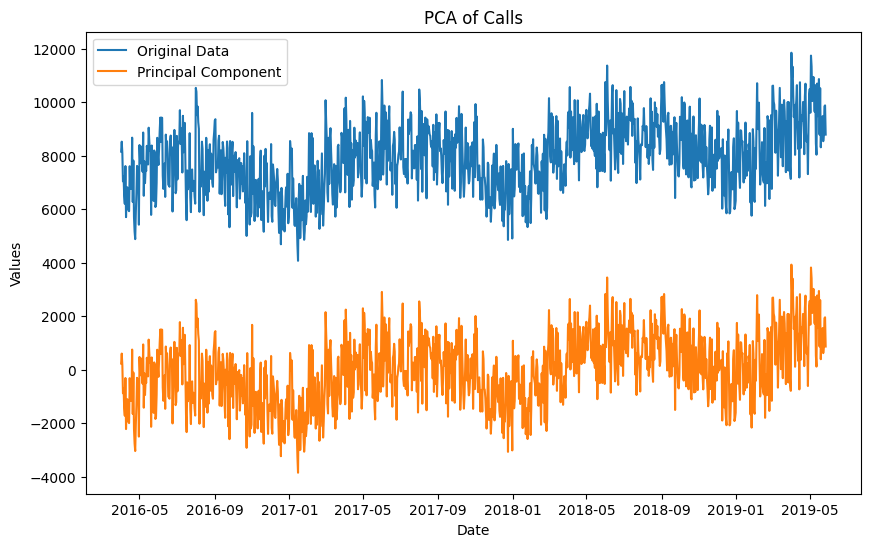

In [26]:
import pandas as pd
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# PCA durchführen
pca = PCA(n_components=1)
principal_components = pca.fit_transform(df[['calls']])

# Ergebnisse in ein DataFrame umwandeln
df_pca = pd.DataFrame(data=principal_components, index=df.index, columns=['principal_component'])

# Ergebnisse anzeigen
print(df_pca)

# Optional: Ergebnisse plotten
plt.figure(figsize=(10, 6))
plt.plot(df.index, df['calls'], label='Original Data')
plt.plot(df_pca.index, df_pca['principal_component'], label='Principal Component')
plt.xlabel('Date')
plt.ylabel('Values')
plt.title('PCA of Calls')
plt.legend()
plt.show()


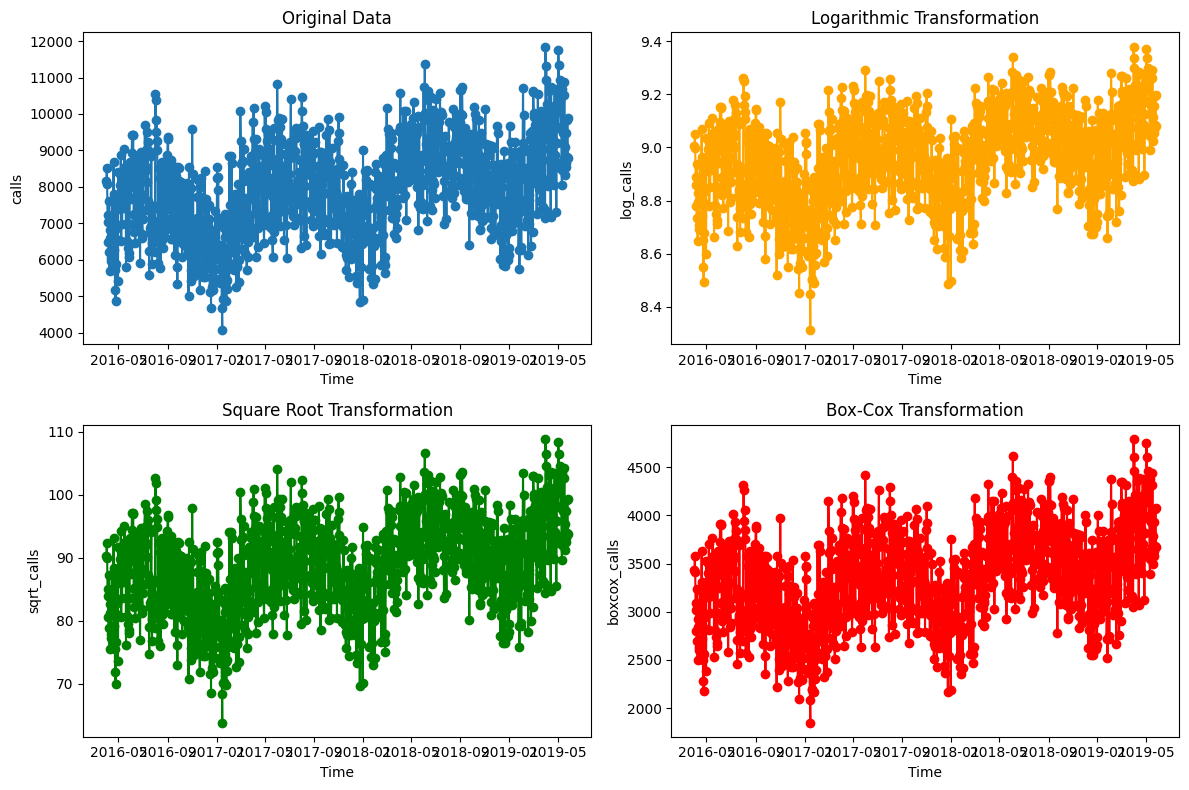

In [27]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Beispiel-Daten erstellen

# Spaltenname als Variable
column_name = 'calls'

# Logarithmische Transformation
df['log_' + column_name] = np.log(df[column_name])

# Quadratwurzel-Transformation
df['sqrt_' + column_name] = np.sqrt(df[column_name])

# Box-Cox-Transformation (erfordert positive Werte)
df['boxcox_' + column_name], _ = stats.boxcox(df[column_name])

# Plot erstellen
plt.figure(figsize=(12, 8))

# Originaldaten plotten
plt.subplot(2, 2, 1)
plt.plot(df.index, df[column_name], marker='o')
plt.title('Original Data')
plt.xlabel('Time')
plt.ylabel(column_name)

# Logarithmische Transformation plotten
plt.subplot(2, 2, 2)
plt.plot(df.index, df['log_' + column_name], marker='o', color='orange')
plt.title('Logarithmic Transformation')
plt.xlabel('Time')
plt.ylabel('log_' + column_name)

# Quadratwurzel-Transformation plotten
plt.subplot(2, 2, 3)
plt.plot(df.index, df['sqrt_' + column_name], marker='o', color='green')
plt.title('Square Root Transformation')
plt.xlabel('Time')
plt.ylabel('sqrt_' + column_name)

# Box-Cox-Transformation plotten
plt.subplot(2, 2, 4)
plt.plot(df.index, df['boxcox_' + column_name], marker='o', color='red')
plt.title('Box-Cox Transformation')
plt.xlabel('Time')
plt.ylabel('boxcox_' + column_name)

plt.tight_layout()
plt.show()


## Additive Decomposition

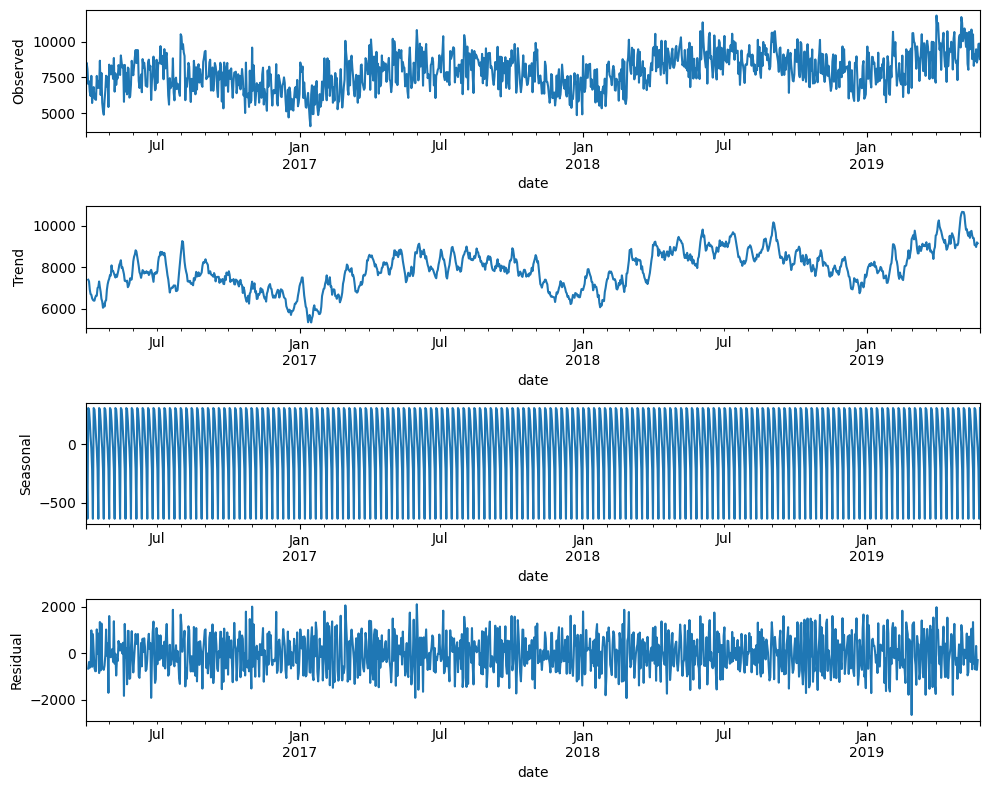

In [28]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt


# Additive Decomposition durchführen
decomposition = sm.tsa.seasonal_decompose(df['calls'], model='additive')

# Komponenten plotten
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(10, 8))
decomposition.observed.plot(ax=ax1)
ax1.set_ylabel('Observed')
decomposition.trend.plot(ax=ax2)
ax2.set_ylabel('Trend')
decomposition.seasonal.plot(ax=ax3)
ax3.set_ylabel('Seasonal')
decomposition.resid.plot(ax=ax4)
ax4.set_ylabel('Residual')
plt.tight_layout()
plt.show()


## Findings

Erkenntnisse: 
- bis auf den Winter wenig Seasonalität bei calls erkennbar

## Plot over weeks

In [29]:
selected_year = 2017

weekly_df = df.copy(deep=True)[df.index.year == selected_year]

target_column_name = "calls"

numer_of_weeks = df.index.isocalendar().week.max()


# New column for each week 
for week in range(1, numer_of_weeks):
    weekly_df[f'week_{week}'] = weekly_df.apply(lambda row: row[target_column_name] if row.name.isocalendar().week == week else None, axis=1)

# Only select week columns
weekly_df = weekly_df[[f'week_{week}' for week in range(1, numer_of_weeks)]]

weekly_df.index = weekly_df.index.dayofweek

display(weekly_df)
display(weekly_df.describe())

,week_1,week_2,week_3,week_4,week_5,week_6,week_7,week_8,week_9,week_10,...,week_42,week_43,week_44,week_45,week_46,week_47,week_48,week_49,week_50,week_51
date,,,,,,,,,,,,,,,,,,,,,
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,8550.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8238.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,7902.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,8268.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,week_1,week_2,week_3,week_4,week_5,week_6,week_7,week_8,week_9,week_10,...,week_42,week_43,week_44,week_45,week_46,week_47,week_48,week_49,week_50,week_51
count,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,...,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000
mean,7497.428571,5346.000000,6026.571429,5745.428571,6972.000000,7511.142857,6603.428571,6408.000000,7860.000000,7946.571429,...,7747.714286,7733.142857,8479.714286,7011.428571,7172.571429,6566.571429,6838.285714,7229.142857,6462.000000,6523.714286
std,1000.638939,779.291986,874.003596,805.884784,1021.175793,964.473506,982.430805,934.132753,1455.656553,946.966887,...,759.805614,662.390476,1157.314379,503.247738,1028.784859,834.545556,896.845902,660.712602,890.456063,966.737075
min,6054.000000,4074.000000,4920.000000,4860.000000,5898.000000,6204.000000,5268.000000,5388.000000,6288.000000,6564.000000,...,6966.000000,6462.000000,7086.000000,6360.000000,5724.000000,5532.000000,6030.000000,6390.000000,5364.000000,4854.000000
25%,6735.000000,5022.000000,5265.000000,5298.000000,6285.000000,6915.000000,5796.000000,5817.000000,6729.000000,7248.000000,...,7248.000000,7602.000000,7425.000000,6645.000000,6582.000000,6087.000000,6096.000000,6834.000000,5859.000000,6042.000000
50%,7902.000000,5418.000000,6300.000000,5442.000000,6786.000000,7398.000000,6816.000000,5994.000000,7338.000000,8166.000000,...,7518.000000,7764.000000,8766.000000,7128.000000,7182.000000,6402.000000,6312.000000,7158.000000,6450.000000,6714.000000
75%,8253.000000,5736.000000,6744.000000,6036.000000,7353.000000,8151.000000,7368.000000,6876.000000,8931.000000,8685.000000,...,8100.000000,8100.000000,9363.000000,7332.000000,7764.000000,7059.000000,7626.000000,7491.000000,7041.000000,7107.000000
max,8550.000000,6414.000000,6948.000000,7248.000000,8844.000000,8844.000000,7812.000000,8088.000000,10074.000000,9030.000000,...,9054.000000,8502.000000,9930.000000,7638.000000,8610.000000,7740.000000,8082.000000,8406.000000,7620.000000,7800.000000


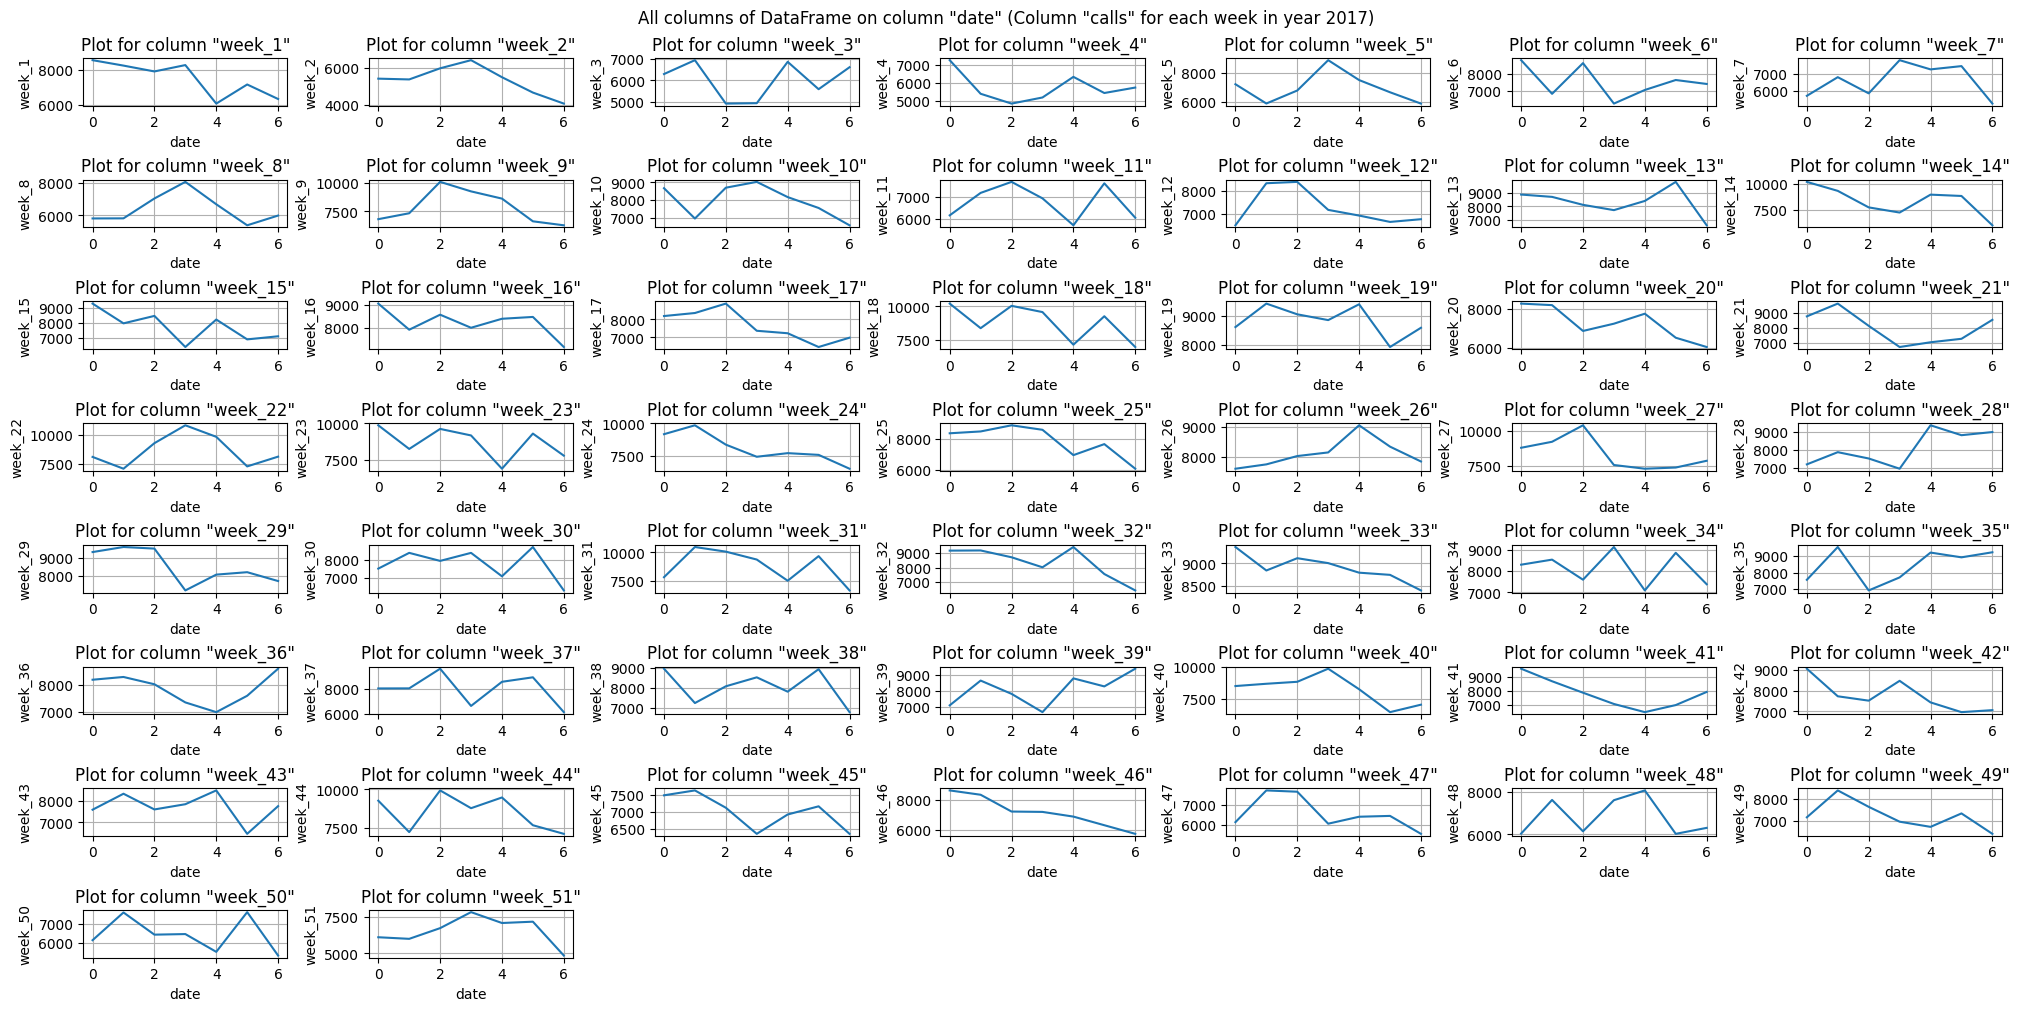

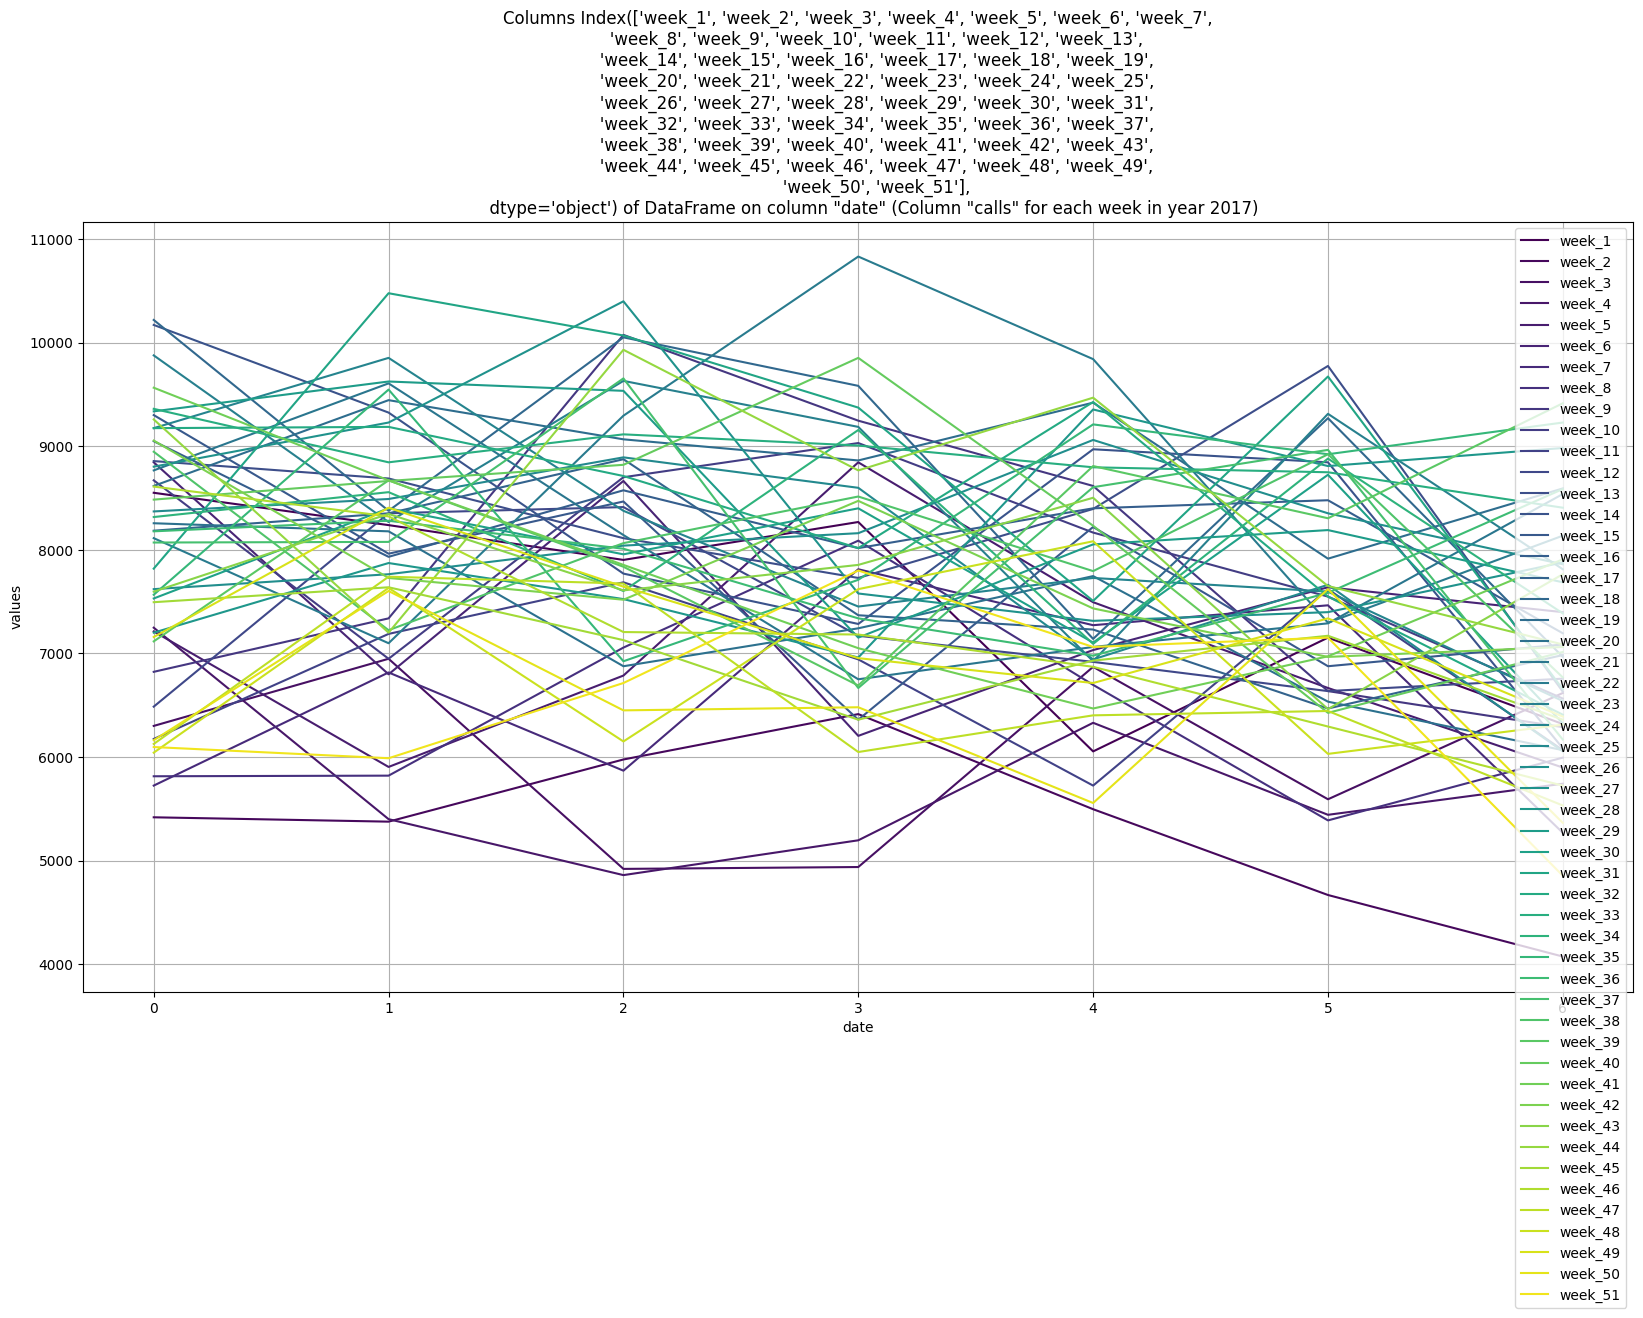

In [30]:
plot_columns_on_index_in_subplots(weekly_df, annotation=f'Column "{target_column_name}" for each week in year {selected_year}')
plot_columns_on_index(weekly_df, annotation=f'Column "{target_column_name}" for each week in year {selected_year}')

# Add new columns based on date

## Extraction of year, month, day_of_week etc

In [31]:
if extended_df is None:
    extended_df = df.copy(deep=True)

extended_df['year'] = extended_df.index.year
extended_df['month'] = extended_df.index.month
extended_df['day_of_week'] = extended_df.index.dayofweek
extended_df['day_of_month'] = extended_df.index.day
extended_df['week_of_year'] = extended_df.index.isocalendar().week
extended_df['day_of_year'] = extended_df.index.dayofyear

## Add weekends

In [32]:
if extended_df is None:
    extended_df = df.copy(deep=True)

extended_df['is_weekend'] = extended_df.index.weekday.isin([5, 6]).astype(bool)
extended_df[["is_weekend"]].describe()

,is_weekend
count,1152
unique,2
top,False
freq,822


## Add holidays

In [33]:
import requests

if extended_df is None:
    extended_df = df.copy(deep=True)


range_of_years = range(extended_df.index.year.min(), extended_df.index.year.max() + 1)

german_state = 'BE' # Notfalldienst aus Berlin

holiday_dates = None

# New column for each month 
for year in range_of_years:
    url = f'https://feiertage-api.de/api/?jahr={year}&nur_land={german_state}&nur_daten=1'
    #url = f'https://feiertage-api.de/api/?jahr={year}&nur_daten=1'

    response = requests.get(url)
    holidays = response.json()

    if holiday_dates is None:
        holiday_dates = [pd.to_datetime(datum) for name, datum in holidays.items()]
    else:
        holiday_dates += [pd.to_datetime(datum) for name, datum in holidays.items()]



print("Count of holiday dates:", len(holiday_dates))
extended_df['is_holiday'] = extended_df.index.isin(holiday_dates).astype(bool)
extended_df[["is_holiday"]].describe()


Count of holiday dates: 84


,is_holiday
count,1152
unique,2
top,False
freq,1088


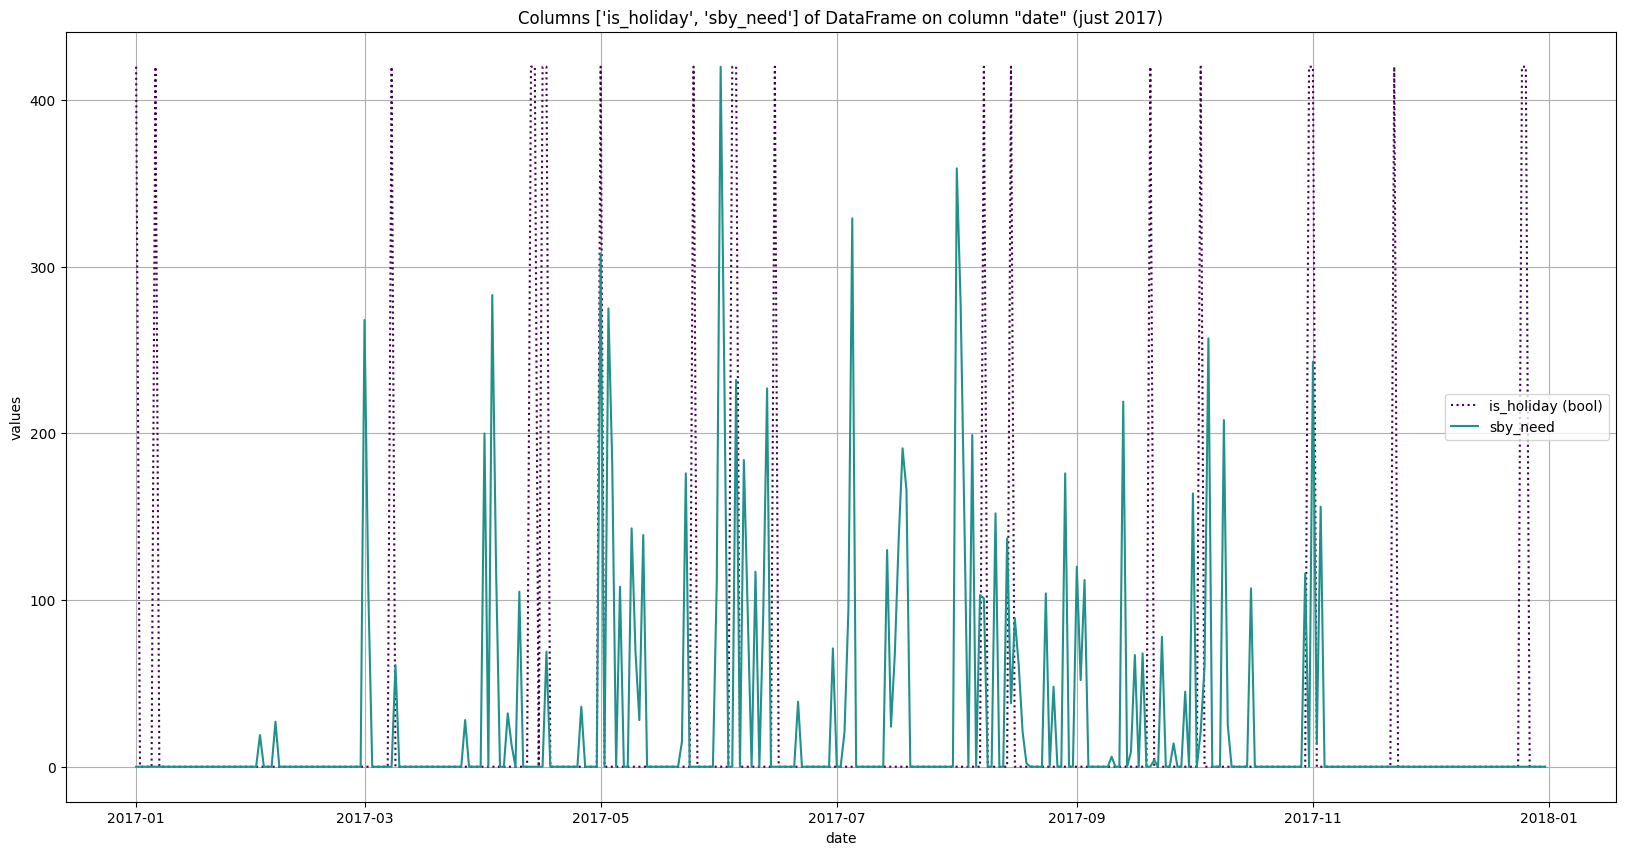

In [34]:
selected_year = 2017

one_year_df = extended_df[extended_df.index.year == selected_year]

one_year_df

plot_columns_on_index(one_year_df, columns=["is_holiday", "sby_need"], annotation=f"just {selected_year}")

## Add temperature

In [35]:
import requests
import pandas as pd
from meteostat import Point, Daily
from datetime import datetime

# Definiere den Standort (Berlin)
berlin = Point(52.5200, 13.4050)

# Definiere den Zeitraum
start = datetime(extended_df.index.year.min(), 1, 1)
end = datetime(extended_df.index.year.max(), 12, 31)

# Lade die Wetterdaten
data = Daily(berlin, start, end)
data = data.fetch()

temperature_columns = ['tavg', "tmin", "tmax"]

# Extrahiere nur die Durchschnittstemperatur
tavg_data = data[temperature_columns]

# To-Do: Evtl mit höchste und Tiefsttemperatur arbeiten

# Füge die Durchschnittstemperatur-Spalte zum DataFrame hinzu
extended_df = extended_df.join(tavg_data, how='left')


In [36]:
extended_df[temperature_columns].describe()

,tavg,tmin,tmax
count,1152.000000,1152.000000,1152.000000
mean,11.268229,7.051997,15.467882
std,7.711124,6.679351,9.095201
min,-8.800000,-12.800000,-5.800000
25%,5.200000,1.900000,7.900000
50%,10.600000,6.700000,14.950000
75%,17.800000,12.400000,23.000000
max,28.900000,23.900000,38.000000


## Plot new columns

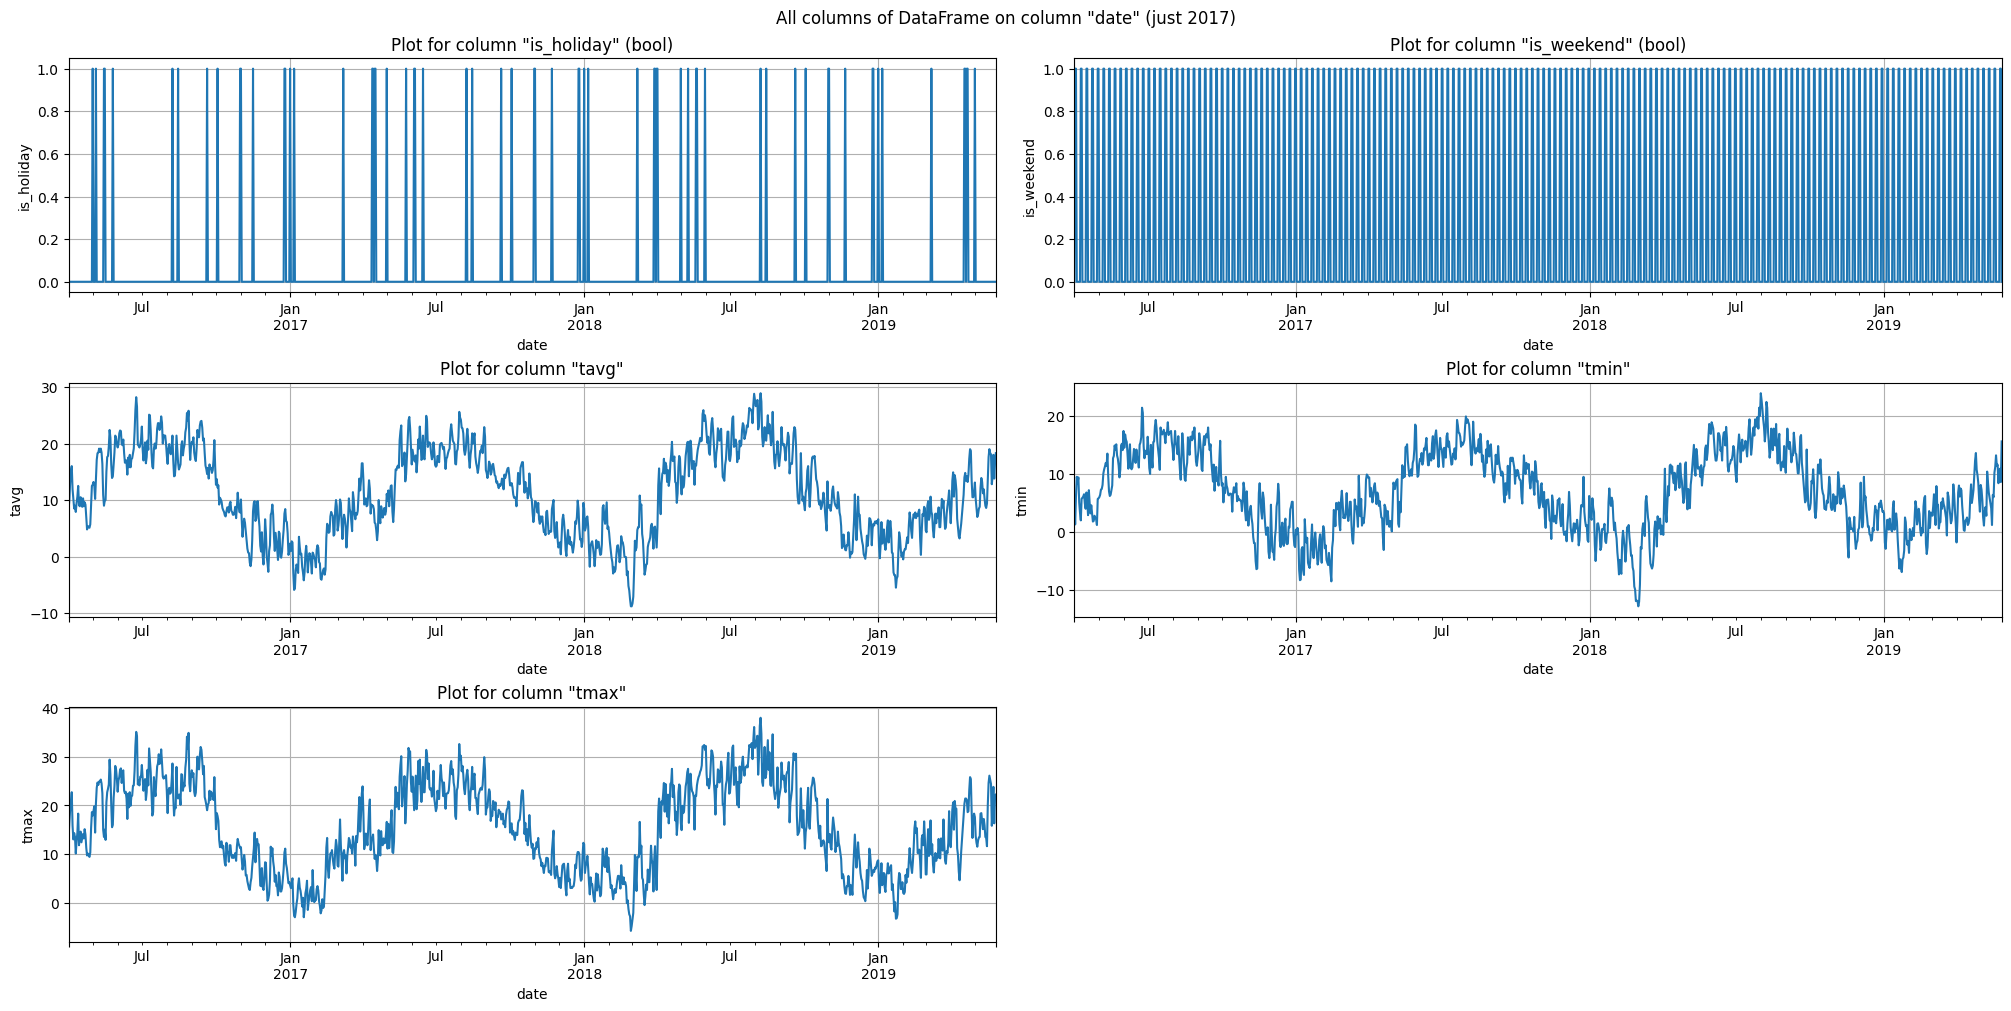

In [37]:
plot_columns_on_index_in_subplots(extended_df, columns=["is_holiday", "is_weekend"] + temperature_columns, annotation=f"just {selected_year}")

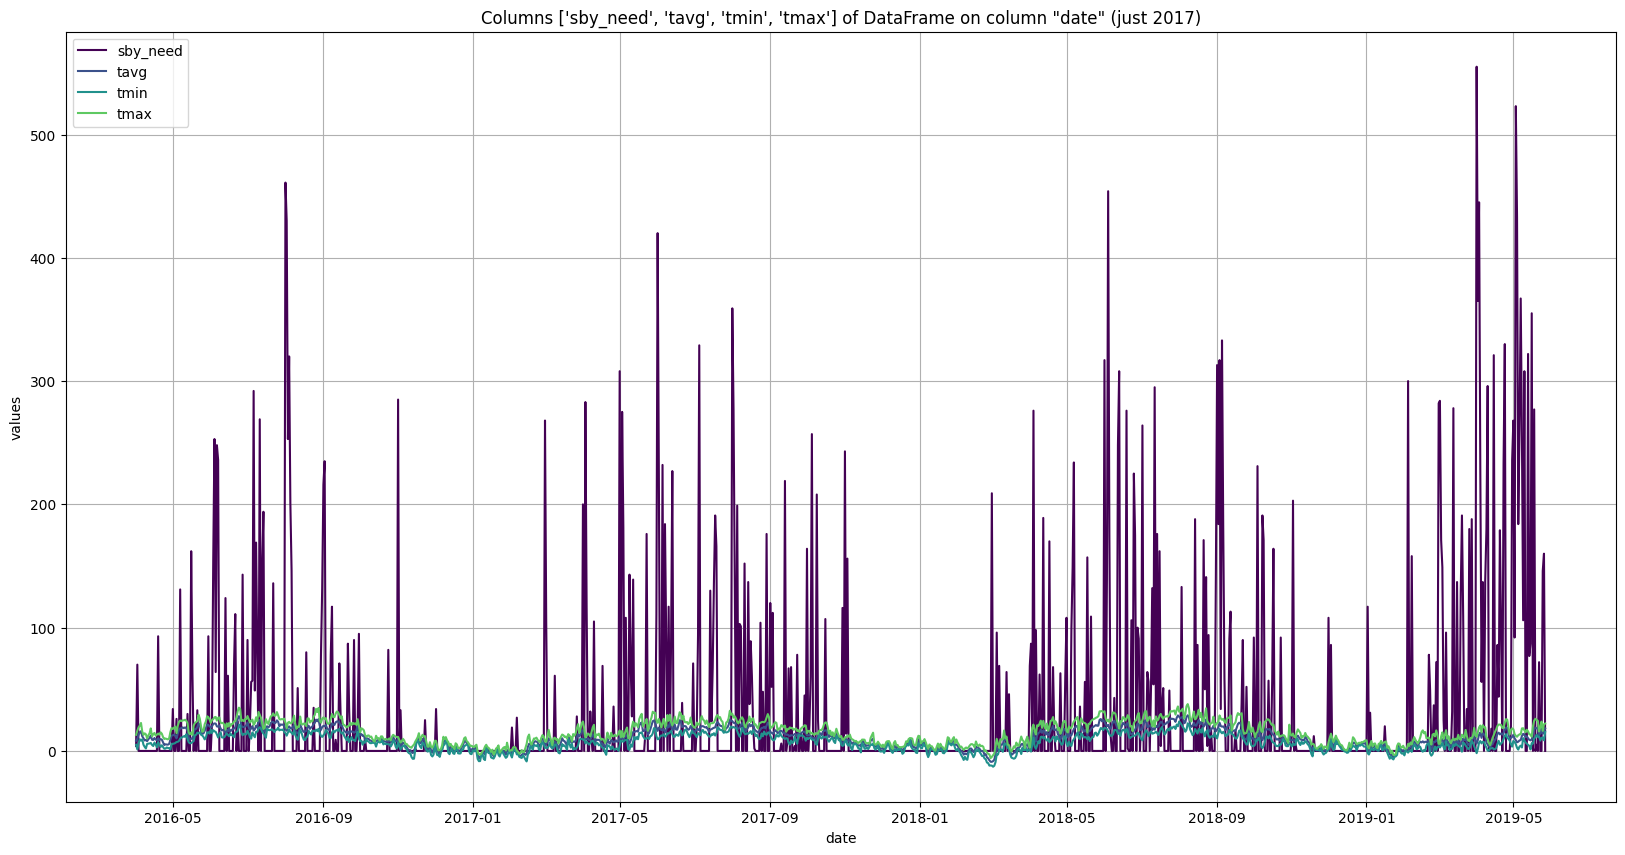

In [38]:
plot_columns_on_index(extended_df, columns=["sby_need"] + temperature_columns, annotation=f"just {selected_year}")

## Correlation matrix for new features

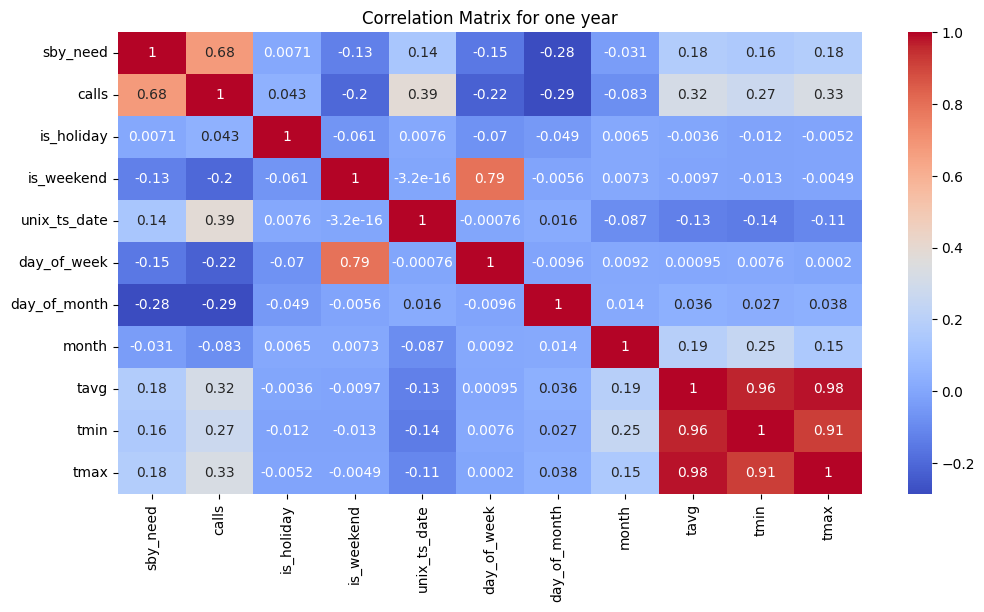

In [39]:

plt.figure(figsize=(12, 6))
sns.heatmap(extended_df[["sby_need", "calls", "is_holiday", "is_weekend", "unix_ts_date", "day_of_week", "day_of_month", "month"] + temperature_columns].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix for one year')
plt.show()

# Analyze biggest outlier

In [40]:
display(extended_df[["calls", "sby_need", "is_weekend", "is_holiday", "tavg", "tmin", "tmax", "day_of_week", "day_of_month", "day_of_year"]].sort_values("sby_need", ascending=False).head(30))

,calls,sby_need,is_weekend,is_holiday,tavg,tmin,tmax,day_of_week,day_of_month,day_of_year
date,,,,,,,,,,
2019-04-01,11850.0,555.0,False,False,5.9,-1.8,11.4,0,1,91
2019-05-03,11742.0,523.0,False,False,8.7,5.5,12.3,4,3,123
2016-08-01,10536.0,461.0,False,False,17.9,14.4,22.8,0,1,214
2018-06-04,11370.0,454.0,False,False,21.2,15.7,25.4,0,4,155
2019-04-03,11328.0,445.0,False,False,13.4,6.8,19.1,2,3,93
2019-05-04,11334.0,433.0,True,False,7.0,2.5,11.5,5,4,124
2016-08-02,10392.0,430.0,False,False,16.4,12.4,18.4,1,2,215
2017-06-01,10830.0,420.0,False,False,16.3,9.5,22.8,3,1,152
2019-05-07,10944.0,367.0,False,False,8.8,4.3,13.5,1,7,127


In [41]:
selected_year = 2019

one_year_df = extended_df[extended_df.index.year == selected_year]


display(one_year_df[["calls", "sby_need", "is_weekend", "is_holiday", "tavg", "tmin", "tmax", "day_of_week", "day_of_month", "day_of_year"]].sort_values("sby_need", ascending=False).head(30))

,calls,sby_need,is_weekend,is_holiday,tavg,tmin,tmax,day_of_week,day_of_month,day_of_year
date,,,,,,,,,,
2019-04-01,11850.0,555.0,False,False,5.9,-1.8,11.4,0,1,91
2019-05-03,11742.0,523.0,False,False,8.7,5.5,12.3,4,3,123
2019-04-03,11328.0,445.0,False,False,13.4,6.8,19.1,2,3,93
2019-05-04,11334.0,433.0,True,False,7.0,2.5,11.5,5,4,124
2019-05-07,10944.0,367.0,False,False,8.8,4.3,13.5,1,7,127
2019-04-02,10920.0,365.0,False,False,8.9,1.7,15.3,1,2,92
2019-05-16,10866.0,355.0,False,False,9.4,6.4,11.6,3,16,136
2019-04-24,10692.0,330.0,False,False,17.3,12.3,23.1,2,24,114
2019-05-13,10698.0,322.0,False,False,10.3,4.9,15.9,0,13,133


# Export data

In [42]:
extended_df.to_csv("../../data/processed/sickness_table.csv")